# EEG Analysis Pipeline — Subject-wise Processing

This notebook is organized to process one participant at a time while preserving the existing signal and PSD visualizations.

**Workflow:** select subject → load four recordings and metadata → preprocess → validate event markers → inspect plots → calculate band power → replace that subject's rows in the master CSV.

Change `SUBJECT_ID` in the configuration cell only. Results are written only after the analysis table has been created successfully.

### Cohort processing shortcut
For cumulative cohort extraction, run the configuration cell, then the **Cohort extraction** cell and **Cohort extraction summary** cell directly below it. These cells validate each subject independently and update the master CSV only for subjects that pass validation. The original single-subject plotting workflow remains below and is preserved.


## 1. Subject selection and project configuration

In [64]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.signal import welch

# Change this value to process another participant.
SUBJECT_ID = "Rc15"
SUBJECT_ID = SUBJECT_ID.replace("sub-", "").strip()
BIDS_SUBJECT = f"sub-{SUBJECT_ID}"

# Find the project root independently of the currently selected subject.
# This allows cohort processing even when one subject folder is missing.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
ROOT = next(
    (
        candidate for candidate in _candidates
        if any(candidate.glob("sub-Rc*"))
    ),
    None
)
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. The current directory or one "
        "of its parents must contain folders such as sub-Rc01."
    )

SUBJECT_DIR = ROOT / BIDS_SUBJECT
RESULTS_DIR = ROOT / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CSV_FILE = RESULTS_DIR / "eeg_analysis_results_math_control.csv"

# Fixed experimental mapping: run-1 = baseline, run-2 = activity.
RECORDINGS = {
    "PRE_Baseline": ("ses-1", 1),
    "PRE_Activity": ("ses-1", 2),
    "POST_Baseline": ("ses-2", 1),
    "POST_Activity": ("ses-2", 2),
}

# Previously selected timestamps. These are provisional until
# validated against the event markers / experimental codebook.
EVENT_TIMES = {
    "PRE": 131.2617188,
    "POST": 99.08984375,
}
EVENT_WINDOW_BEFORE = 2.0
EVENT_WINDOW_AFTER = 3.0

# Acquisition JSON reports a 60-Hz notch already applied by OpenVibe.
# Do not apply another notch by default. Set True only if justified
# after inspecting the PSD and confirming the acquisition history.
APPLY_ADDITIONAL_NOTCH = False
POWER_LINE_FREQUENCY = 60

print("Selected subject (legacy single-subject cells):", BIDS_SUBJECT)
print("Project root:", ROOT)
print("Results CSV:", CSV_FILE)

Selected subject (legacy single-subject cells): sub-Rc15
Project root: /Users/ananyosen/Documents/Term Project
Results CSV: /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_math_control.csv


## Cohort extraction — process only complete, consistent subjects

**Use this section for the master CSV.** Run the configuration cell immediately above, then run the two cohort cells below. You do not need to run the plotting / single-subject cells to extract cohort band-power results.

- `SUBJECTS_TO_PROCESS` can contain all expected subjects (`Rc01`–`Rc16`) or just one subject (for example, `["Rc15"]`) when retrying a corrected recording.
- A subject is accepted only when all four `.set`, `.json`, and `channels.tsv` files exist, all four SET files load, the signals contain finite data, and channel names / order and sampling frequency agree across the four recordings.
- Activity `events.tsv` files are recorded in the audit but are **not required** for whole-recording band power. They are needed for event-specific analyses.
- Invalid subjects are skipped without stopping the other subjects. Their reasons are written to a cumulative quality-control summary that is updated across separate notebook runs.
- Existing master-CSV rows are replaced only for subjects successfully reprocessed. Skipped subjects' existing rows, if any, are left untouched.


In [65]:
# ---------- COHORT SETTINGS ----------
# Process the full expected cohort, or change this to a smaller list when retrying.
SUBJECTS_TO_PROCESS = [f"Re{i:02d}" for i in range(1, 20)]
# Example for a single retry:
# SUBJECTS_TO_PROCESS = ["Rc15"]

REQUIRE_JSON_AND_CHANNELS_TSV = True
EXPECTED_CHANNEL_COUNT = 32

COHORT_CSV_FILE = ROOT / "Results" / "eeg_analysis_results_read_experiment.csv"
COHORT_AUDIT_FILE = ROOT / "Results" / "subject_processing_summary_read_experiment.csv"
COHORT_CSV_FILE.parent.mkdir(parents=True, exist_ok=True)

COHORT_RECORDINGS = {
    "PRE_Baseline": ("ses-1", 1),
    "PRE_Activity": ("ses-1", 2),
    "POST_Baseline": ("ses-2", 1),
    "POST_Activity": ("ses-2", 2),
}

COHORT_BANDS = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 50.0),
}
COHORT_TOTAL_RANGE = (0.5, 50.0)

COHORT_CSV_COLUMNS = [
    "subject_id", "session", "run", "condition",
    "sampling_frequency", "duration", "channel_count", "sample_count",
    "channel", "band", "frequency_min", "frequency_max",
    "absolute_power", "relative_power",
    "event_id", "event_onset", "event_duration", "event_code"
]

def _cohort_integrate_psd(freqs, psd, low, high):
    mask = (freqs >= low) & (freqs <= high)
    if mask.sum() < 2:
        return np.nan
    # np.trapezoid is the current NumPy API; fallback supports older installations.
    integrate = getattr(np, "trapezoid", None)
    if integrate is None:
        integrate = np.trapz
    return float(integrate(psd[mask], freqs[mask]))

def _cohort_validate_and_load(subject_id):
    subject_dir = ROOT / f"sub-{subject_id}"
    if not subject_dir.is_dir():
        raise FileNotFoundError(f"Subject folder not found: {subject_dir}")

    loaded = {}
    paths = {}
    missing = []

    for rec_name, (session, run) in COHORT_RECORDINGS.items():
        eeg_dir = subject_dir / session / "eeg"
        prefix = f"sub-{subject_id}_{session}_task-SmartickDataset_run-{run}"
        files = {
            "SET": eeg_dir / f"{prefix}_eeg.set",
            "JSON": eeg_dir / f"{prefix}_eeg.json",
            "channels.tsv": eeg_dir / f"{prefix}_channels.tsv",
        }
        for kind, path in files.items():
            if kind == "SET" or REQUIRE_JSON_AND_CHANNELS_TSV:
                if not path.is_file():
                    missing.append(f"{rec_name}: missing {kind} ({path.name})")

        if files["SET"].is_file():
            paths[rec_name] = files

    if missing:
        raise ValueError("; ".join(missing))

    for rec_name, files in paths.items():
        try:
            raw = mne.io.read_raw_eeglab(files["SET"], preload=True, verbose="ERROR")
        except Exception as exc:
            raise RuntimeError(
                f"{rec_name}: SET could not be loaded ({type(exc).__name__}: {exc})"
            ) from exc

        if raw.n_times < 2 or len(raw.ch_names) == 0:
            raise ValueError(f"{rec_name}: empty signal or no channels")

        data = raw.get_data()
        if not np.isfinite(data).all():
            raise ValueError(f"{rec_name}: signal contains NaN or infinite samples")

        with open(files["JSON"], "r", encoding="utf-8") as f:
            metadata = json.load(f)

        channel_table = pd.read_csv(files["channels.tsv"], sep="\t")
        if "name" not in channel_table.columns:
            raise ValueError(f"{rec_name}: channels.tsv has no 'name' column")

        tsv_names = channel_table["name"].astype(str).tolist()
        if tsv_names != raw.ch_names:
            raise ValueError(
                f"{rec_name}: channels.tsv names/order do not match SET channel names"
            )

        loaded[rec_name] = {
            "raw": raw,
            "metadata": metadata,
            "files": files,
            "events_file": (
                files["SET"].with_name(files["SET"].name.replace("_eeg.set", "_events.tsv"))
            ),
        }

    # Cross-recording consistency checks.
    first_name = list(loaded)[0]
    reference_raw = loaded[first_name]["raw"]
    reference_channels = reference_raw.ch_names
    reference_sfreq = float(reference_raw.info["sfreq"])

    if len(reference_channels) != EXPECTED_CHANNEL_COUNT:
        raise ValueError(
            f"{first_name}: expected {EXPECTED_CHANNEL_COUNT} channels, "
            f"found {len(reference_channels)}"
        )

    for rec_name, item in loaded.items():
        raw = item["raw"]
        if raw.ch_names != reference_channels:
            raise ValueError(
                f"{rec_name}: channel names or order differ from {first_name}"
            )
        if not np.isclose(float(raw.info["sfreq"]), reference_sfreq):
            raise ValueError(
                f"{rec_name}: sampling frequency {raw.info['sfreq']} Hz "
                f"differs from {reference_sfreq} Hz"
            )
        if raw.info["sfreq"] / 2 < max(high for _, high in COHORT_BANDS.values()):
            raise ValueError(f"{rec_name}: Nyquist frequency is below 50 Hz")

    return loaded

def _cohort_extract_subject(subject_id):
    loaded = _cohort_validate_and_load(subject_id)
    rows = []

    for rec_name, item in loaded.items():
        raw = item["raw"].copy()
        raw.filter(l_freq=0.5, h_freq=50.0, fir_design="firwin", verbose="ERROR")

        session, run = COHORT_RECORDINGS[rec_name]
        condition = "Baseline" if run == 1 else "Activity"
        sfreq = float(raw.info["sfreq"])
        nperseg = min(2048, raw.n_times)

        if nperseg < 16:
            raise ValueError(f"{rec_name}: recording is too short for Welch PSD")

        for channel in raw.ch_names:
            signal_uv = raw.get_data(picks=[channel])[0] * 1e6
            freqs, psd = welch(
                signal_uv,
                fs=sfreq,
                nperseg=nperseg,
                noverlap=nperseg // 2,
                scaling="density"
            )
            total_power = _cohort_integrate_psd(
                freqs, psd, *COHORT_TOTAL_RANGE
            )

            for band, (low, high) in COHORT_BANDS.items():
                absolute_power = _cohort_integrate_psd(freqs, psd, low, high)
                relative_power = (
                    absolute_power / total_power * 100
                    if np.isfinite(total_power) and total_power > 0
                    else np.nan
                )
                if not np.isfinite(absolute_power) or not np.isfinite(relative_power):
                    raise ValueError(
                        f"{rec_name}, {channel}, {band}: non-finite band-power result"
                    )

                rows.append({
                    "subject_id": subject_id,
                    "session": session,
                    "run": run,
                    "condition": condition,
                    "sampling_frequency": sfreq,
                    "duration": float(raw.times[-1]),
                    "channel_count": len(raw.ch_names),
                    "sample_count": raw.n_times,
                    "channel": channel,
                    "band": band,
                    "frequency_min": low,
                    "frequency_max": high,
                    "absolute_power": absolute_power,
                    "relative_power": relative_power,
                    "event_id": "",
                    "event_onset": np.nan,
                    "event_duration": np.nan,
                    "event_code": "",
                })

    result = pd.DataFrame(rows, columns=COHORT_CSV_COLUMNS)
    expected_rows = 4 * EXPECTED_CHANNEL_COUNT * len(COHORT_BANDS)
    if len(result) != expected_rows:
        raise ValueError(
            f"Expected {expected_rows} rows but generated {len(result)}"
        )
    return result, loaded

# Process each subject independently. A failure for one subject does not stop the cohort.
cohort_audit_rows = []
successfully_extracted_subjects = []
all_new_results = []

for subject in SUBJECTS_TO_PROCESS:
    subject_id = str(subject).replace("sub-", "").strip()
    print(f"\\nProcessing {subject_id} ...")
    try:
        subject_df, loaded_recordings = _cohort_extract_subject(subject_id)
        all_new_results.append(subject_df)
        successfully_extracted_subjects.append(subject_id)

        events_status = {}
        for rec_name, item in loaded_recordings.items():
            events_path = item["events_file"]
            events_status[rec_name] = events_path.is_file()

        cohort_audit_rows.append({
            "subject_id": subject_id,
            "status": "EXTRACTED",
            "recordings_loaded": 4,
            "band_power_rows": len(subject_df),
            "missing_or_inconsistent_reason": "",
            "PRE_Activity_events_file": events_status.get("PRE_Activity", False),
            "POST_Activity_events_file": events_status.get("POST_Activity", False),
        })
        print(f"  SUCCESS — {len(subject_df)} band-power rows")
    except Exception as exc:
        cohort_audit_rows.append({
            "subject_id": subject_id,
            "status": "SKIPPED",
            "recordings_loaded": 0,
            "band_power_rows": 0,
            "missing_or_inconsistent_reason": f"{type(exc).__name__}: {exc}",
            "PRE_Activity_events_file": False,
            "POST_Activity_events_file": False,
        })
        print(f"  SKIPPED — {type(exc).__name__}: {exc}")

# Update the master CSV only with successfully completed subjects.
if all_new_results:
    new_cohort_results = pd.concat(all_new_results, ignore_index=True)

    if COHORT_CSV_FILE.exists():
        existing = pd.read_csv(COHORT_CSV_FILE)
        for col in COHORT_CSV_COLUMNS:
            if col not in existing.columns:
                existing[col] = np.nan
        existing = existing[COHORT_CSV_COLUMNS]
        existing["subject_id"] = (
            existing["subject_id"].astype(str)
            .str.replace("sub-", "", regex=False)
        )
        existing = existing[
            ~existing["subject_id"].isin(successfully_extracted_subjects)
        ]
    else:
        existing = pd.DataFrame(columns=COHORT_CSV_COLUMNS)

    combined = pd.concat(
        [existing, new_cohort_results[COHORT_CSV_COLUMNS]],
        ignore_index=True
    )
    combined["event_id"] = combined["event_id"].fillna("").astype(str)
    combined = combined.drop_duplicates(
        subset=["subject_id", "session", "run", "channel", "band", "event_id"],
        keep="last"
    )
    combined = combined.sort_values(
        ["subject_id", "session", "run", "channel", "band"]
    ).reset_index(drop=True)

    temp_path = COHORT_CSV_FILE.with_name(COHORT_CSV_FILE.name + ".tmp")
    combined.to_csv(temp_path, index=False)
    temp_path.replace(COHORT_CSV_FILE)

    print("\\nMaster CSV updated:", COHORT_CSV_FILE)
    print("Subjects successfully extracted this run:", successfully_extracted_subjects)
else:
    print("\\nNo subjects passed validation. Existing master CSV was not changed.")

# Keep a cumulative audit across separate notebook runs.
# Reprocessing a subject updates that subject's previous audit entry.
current_audit = pd.DataFrame(cohort_audit_rows)
if COHORT_AUDIT_FILE.exists():
    previous_audit = pd.read_csv(COHORT_AUDIT_FILE)
    if not previous_audit.empty and not current_audit.empty:
        attempted_ids = current_audit["subject_id"].astype(str).tolist()
        previous_audit = previous_audit[
            ~previous_audit["subject_id"].astype(str).isin(attempted_ids)
        ]
    cohort_audit_df = pd.concat(
        [previous_audit, current_audit], ignore_index=True
    )
else:
    cohort_audit_df = current_audit.copy()

if not cohort_audit_df.empty:
    cohort_audit_df = cohort_audit_df.sort_values(
        "subject_id"
    ).reset_index(drop=True)
    cohort_audit_df.to_csv(COHORT_AUDIT_FILE, index=False)

# Explicit lists for downstream cells: only fully validated subjects are eligible.
VALID_SUBJECTS = successfully_extracted_subjects.copy()
SKIPPED_SUBJECTS = [
    row["subject_id"] for row in cohort_audit_rows
    if row["status"] == "SKIPPED"
]
print("\\nEligible subjects for downstream single-subject plots:", VALID_SUBJECTS)
print("Skipped subjects (not eligible for further analysis):", SKIPPED_SUBJECTS)


\nProcessing Re01 ...
  SUCCESS — 640 band-power rows
\nProcessing Re02 ...
  SKIPPED — ValueError: PRE_Activity: missing SET (sub-Re02_ses-1_task-SmartickDataset_run-2_eeg.set); PRE_Activity: missing JSON (sub-Re02_ses-1_task-SmartickDataset_run-2_eeg.json); PRE_Activity: missing channels.tsv (sub-Re02_ses-1_task-SmartickDataset_run-2_channels.tsv)
\nProcessing Re03 ...
  SUCCESS — 640 band-power rows
\nProcessing Re04 ...
  SUCCESS — 640 band-power rows
\nProcessing Re05 ...
  SUCCESS — 640 band-power rows
\nProcessing Re06 ...
  SKIPPED — ValueError: PRE_Activity: missing SET (sub-Re06_ses-1_task-SmartickDataset_run-2_eeg.set); PRE_Activity: missing JSON (sub-Re06_ses-1_task-SmartickDataset_run-2_eeg.json); PRE_Activity: missing channels.tsv (sub-Re06_ses-1_task-SmartickDataset_run-2_channels.tsv)
\nProcessing Re07 ...
  SUCCESS — 640 band-power rows
\nProcessing Re08 ...
  SUCCESS — 640 band-power rows
\nProcessing Re09 ...
  SUCCESS — 640 band-power rows
\nProcessing Re10 ...
  SU

## Cohort extraction summary

Run this cell after the cohort extraction cell. It shows exactly which subjects were extracted and which were skipped, with the validation reason. The same report is saved as `Results/subject_processing_summary.csv`.


In [66]:
# Display the cumulative cohort-level processing summary.
if COHORT_AUDIT_FILE.exists():
    cohort_audit_df = pd.read_csv(COHORT_AUDIT_FILE)

if not cohort_audit_df.empty:

    extracted = cohort_audit_df.loc[
        cohort_audit_df["status"] == "EXTRACTED", "subject_id"
    ].tolist()
    skipped = cohort_audit_df.loc[
        cohort_audit_df["status"] == "SKIPPED", "subject_id"
    ].tolist()

    print("SUBJECTS SUCCESSFULLY EXTRACTED:")
    print(extracted if extracted else "None")

    print("\\nSUBJECTS SKIPPED:")
    print(skipped if skipped else "None")

    print("\\nSUMMARY COUNTS")
    print("Processed:", len(cohort_audit_df))
    print("Extracted:", len(extracted))
    print("Skipped:", len(skipped))

    print("\\nDETAILED VALIDATION REPORT")
    display(cohort_audit_df)

    print("\\nAudit report saved to:", COHORT_AUDIT_FILE)
    print("Master results CSV:", COHORT_CSV_FILE)
else:
    print("No subjects were processed. Run the cohort extraction cell first.")


SUBJECTS SUCCESSFULLY EXTRACTED:
['Re01', 'Re03', 'Re04', 'Re05', 'Re07', 'Re08', 'Re09', 'Re10', 'Re11', 'Re12', 'Re13', 'Re14', 'Re15', 'Re16', 'Re17', 'Re18', 'Re19']
\nSUBJECTS SKIPPED:
['Re02', 'Re06']
\nSUMMARY COUNTS
Processed: 19
Extracted: 17
Skipped: 2
\nDETAILED VALIDATION REPORT


,subject_id,status,recordings_loaded,band_power_rows,missing_or_inconsistent_reason,PRE_Activity_events_file,POST_Activity_events_file
0,Re01,EXTRACTED,4,640,NaN,True,True
1,Re02,SKIPPED,0,0,ValueError: PRE_Activity: missing SET (sub-Re0...,False,False
2,Re03,EXTRACTED,4,640,NaN,True,True
3,Re04,EXTRACTED,4,640,NaN,True,True
4,Re05,EXTRACTED,4,640,NaN,True,True
5,Re06,SKIPPED,0,0,ValueError: PRE_Activity: missing SET (sub-Re0...,False,False
6,Re07,EXTRACTED,4,640,NaN,True,True
7,Re08,EXTRACTED,4,640,NaN,True,True
8,Re09,EXTRACTED,4,640,NaN,True,True
9,Re10,EXTRACTED,4,640,NaN,True,True


\nAudit report saved to: /Users/ananyosen/Documents/Term Project/Results/subject_processing_summary_read_experiment.csv
Master results CSV: /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_read_experiment.csv


## 2. Load SET recordings, JSON metadata, and event tables
The four recordings are loaded by BIDS filename. JSON and TSV files are optional per run; missing event files are recorded as unavailable rather than stopping the pipeline.

In [67]:
# Load one subject for the legacy plotting / visualization cells below.
# The cohort extraction cell above validates all four recordings first.
# A skipped subject is NEVER loaded again in this section.

if "VALID_SUBJECTS" not in globals():
    raise RuntimeError(
        "Run the cohort extraction cell above first. It creates VALID_SUBJECTS "
        "and SKIPPED_SUBJECTS."
    )

if not VALID_SUBJECTS:
    raise RuntimeError(
        "No subjects passed validation. The plotting section is stopped; "
        "skipped subjects will not be loaded."
    )

# Keep the configured subject if it passed validation.
# Otherwise, select the first subject that passed all four-recording checks.
if SUBJECT_ID not in VALID_SUBJECTS:
    requested_subject = SUBJECT_ID
    SUBJECT_ID = VALID_SUBJECTS[0]
    BIDS_SUBJECT = f"sub-{SUBJECT_ID}"
    SUBJECT_DIR = ROOT / BIDS_SUBJECT
    print(
        f"{requested_subject} was skipped during cohort validation. "
        f"Switching plotting cells to the first valid subject: {SUBJECT_ID}"
    )
else:
    BIDS_SUBJECT = f"sub-{SUBJECT_ID}"
    SUBJECT_DIR = ROOT / BIDS_SUBJECT

raw_files = {}
recording_metadata = {}
event_tables = {}
recording_paths = {}
channel_tables = {}

load_error = None

for name, (session, run) in RECORDINGS.items():
    eeg_dir = SUBJECT_DIR / session / "eeg"
    prefix = (
        f"{BIDS_SUBJECT}_{session}_"
        f"task-SmartickDataset_run-{run}"
    )

    set_file = eeg_dir / f"{prefix}_eeg.set"
    json_file = eeg_dir / f"{prefix}_eeg.json"
    events_file = eeg_dir / f"{prefix}_events.tsv"
    channels_file = eeg_dir / f"{prefix}_channels.tsv"

    try:
        raw = mne.io.read_raw_eeglab(
            set_file, preload=True, verbose="ERROR"
        )
    except Exception as exc:
        load_error = (
            f"{name}: {type(exc).__name__}: {exc}"
        )
        break

    raw_files[name] = raw
    recording_paths[name] = set_file

    if json_file.exists():
        with open(json_file, "r", encoding="utf-8") as f:
            recording_metadata[name] = json.load(f)
    else:
        recording_metadata[name] = {}

    event_tables[name] = (
        pd.read_csv(events_file, sep="\t")
        if events_file.exists()
        else pd.DataFrame()
    )

    channel_tables[name] = (
        pd.read_csv(channels_file, sep="\t")
        if channels_file.exists()
        else pd.DataFrame()
    )

if load_error is not None or len(raw_files) != len(RECORDINGS):
    # Do not leave partially loaded recordings available to later cells.
    raw_files = {}
    recording_metadata = {}
    event_tables = {}
    recording_paths = {}
    channel_tables = {}
    raise RuntimeError(
        f"Selected subject {SUBJECT_ID} could not be loaded completely "
        f"after validation. Partial recordings have been discarded. "
        f"Details: {load_error or 'one or more recordings were not loaded'}"
    )

for name, raw in raw_files.items():
    print(f"\\n{name}: {recording_paths[name].name}")
    print(
        f"  channels={len(raw.ch_names)}, "
        f"sfreq={raw.info['sfreq']} Hz, "
        f"duration={raw.times[-1]:.3f} s, "
        f"samples={raw.n_times}, "
        f"events={len(event_tables[name])}"
    )

# Backward-compatible aliases used by the existing plotting cells.
raw1 = raw_files["PRE_Baseline"]
raw2 = raw_files["PRE_Activity"]
raw3 = raw_files["POST_Baseline"]
raw4 = raw_files["POST_Activity"]


Rc15 was skipped during cohort validation. Switching plotting cells to the first valid subject: Re01
\nPRE_Baseline: sub-Re01_ses-1_task-SmartickDataset_run-1_eeg.set
  channels=32, sfreq=256.0 Hz, duration=179.996 s, samples=46080, events=0
\nPRE_Activity: sub-Re01_ses-1_task-SmartickDataset_run-2_eeg.set
  channels=32, sfreq=256.0 Hz, duration=155.352 s, samples=39771, events=5
\nPOST_Baseline: sub-Re01_ses-2_task-SmartickDataset_run-1_eeg.set
  channels=32, sfreq=256.0 Hz, duration=179.996 s, samples=46080, events=0
\nPOST_Activity: sub-Re01_ses-2_task-SmartickDataset_run-2_eeg.set
  channels=32, sfreq=256.0 Hz, duration=123.531 s, samples=31625, events=8


## 3. Preprocess all four recordings
Apply the same 0.5–50 Hz band-pass filter to every run. The source JSON describes an acquisition-stage 60-Hz notch; therefore, an additional notch is disabled by default to avoid unnecessary repeated filtering.

In [68]:
raw_clean_files = {}

for name, raw in raw_files.items():
    raw_clean = raw.copy()
    raw_clean.filter(
        l_freq=0.5,
        h_freq=50.0,
        fir_design="firwin",
        verbose=False
    )

    if APPLY_ADDITIONAL_NOTCH:
        raw_clean.notch_filter(
            freqs=POWER_LINE_FREQUENCY,
            verbose=False
        )

    raw_clean_files[name] = raw_clean

raw_clean1 = raw_clean_files["PRE_Baseline"]
raw_clean2 = raw_clean_files["PRE_Activity"]
raw_clean3 = raw_clean_files["POST_Baseline"]
raw_clean4 = raw_clean_files["POST_Activity"]

print("Preprocessing completed for", len(raw_clean_files), "recordings.")
print("Band-pass: 0.5–50 Hz")
print("Additional notch applied:", APPLY_ADDITIONAL_NOTCH)

Preprocessing completed for 4 recordings.
Band-pass: 0.5–50 Hz
Additional notch applied: False


## 4. Validate activity event markers
This cell checks whether the provisional PRE/POST timestamps overlap with events listed in each activity run's `events.tsv`. A missing duration is treated as a point event for overlap checking; it does **not** establish the duration of the underlying activity. Event-code meanings must be confirmed from the experiment's codebook.

In [69]:
def events_overlapping_window(events, center, before=2.0, after=3.0):
    if events.empty or "onset" not in events.columns:
        return pd.DataFrame()

    table = events.copy()
    table["onset"] = pd.to_numeric(table["onset"], errors="coerce")
    if "duration" not in table.columns:
        table["duration"] = 0.0
    table["duration"] = pd.to_numeric(
        table["duration"], errors="coerce"
    ).fillna(0.0)
    table["event_end"] = table["onset"] + table["duration"]

    start = center - before
    end = center + after
    return table[
        table["onset"].notna()
        & (table["onset"] <= end)
        & (table["event_end"] >= start)
    ].copy()


event_validation_rows = []

for session_label, recording_name in [
    ("PRE", "PRE_Activity"),
    ("POST", "POST_Activity")
]:
    timestamp = EVENT_TIMES[session_label]
    events = event_tables[recording_name]
    overlapping = events_overlapping_window(
        events,
        timestamp,
        EVENT_WINDOW_BEFORE,
        EVENT_WINDOW_AFTER
    )

    event_validation_rows.append({
        "session": session_label,
        "recording": recording_name,
        "candidate_timestamp": timestamp,
        "window_start": timestamp - EVENT_WINDOW_BEFORE,
        "window_end": timestamp + EVENT_WINDOW_AFTER,
        "events_file_available": not events.empty,
        "overlapping_event_count": len(overlapping),
        "validation": (
            "marker found in window"
            if len(overlapping)
            else "no marker found in window / events unavailable"
        )
    })

    print(f"\n{session_label} activity — candidate {timestamp:.4f} s")
    if overlapping.empty:
        print("No event marker overlaps the selected analysis window.")
    else:
        display(overlapping)

event_validation_df = pd.DataFrame(event_validation_rows)
display(event_validation_df)


PRE activity — candidate 131.2617 s
No event marker overlaps the selected analysis window.

POST activity — candidate 99.0898 s


,onset,duration,sample,value,event_end
3,98.246094,0.0,25151,33028,98.246094
4,98.269531,0.0,25157,33057,98.269531


,session,recording,candidate_timestamp,window_start,window_end,events_file_available,overlapping_event_count,validation
0,PRE,PRE_Activity,131.261719,129.261719,134.261719,True,0,no marker found in window / events unavailable
1,POST,POST_Activity,99.089844,97.089844,102.089844,True,2,marker found in window


## 5. Signal plots — baseline vs activity
Existing visualization retained.

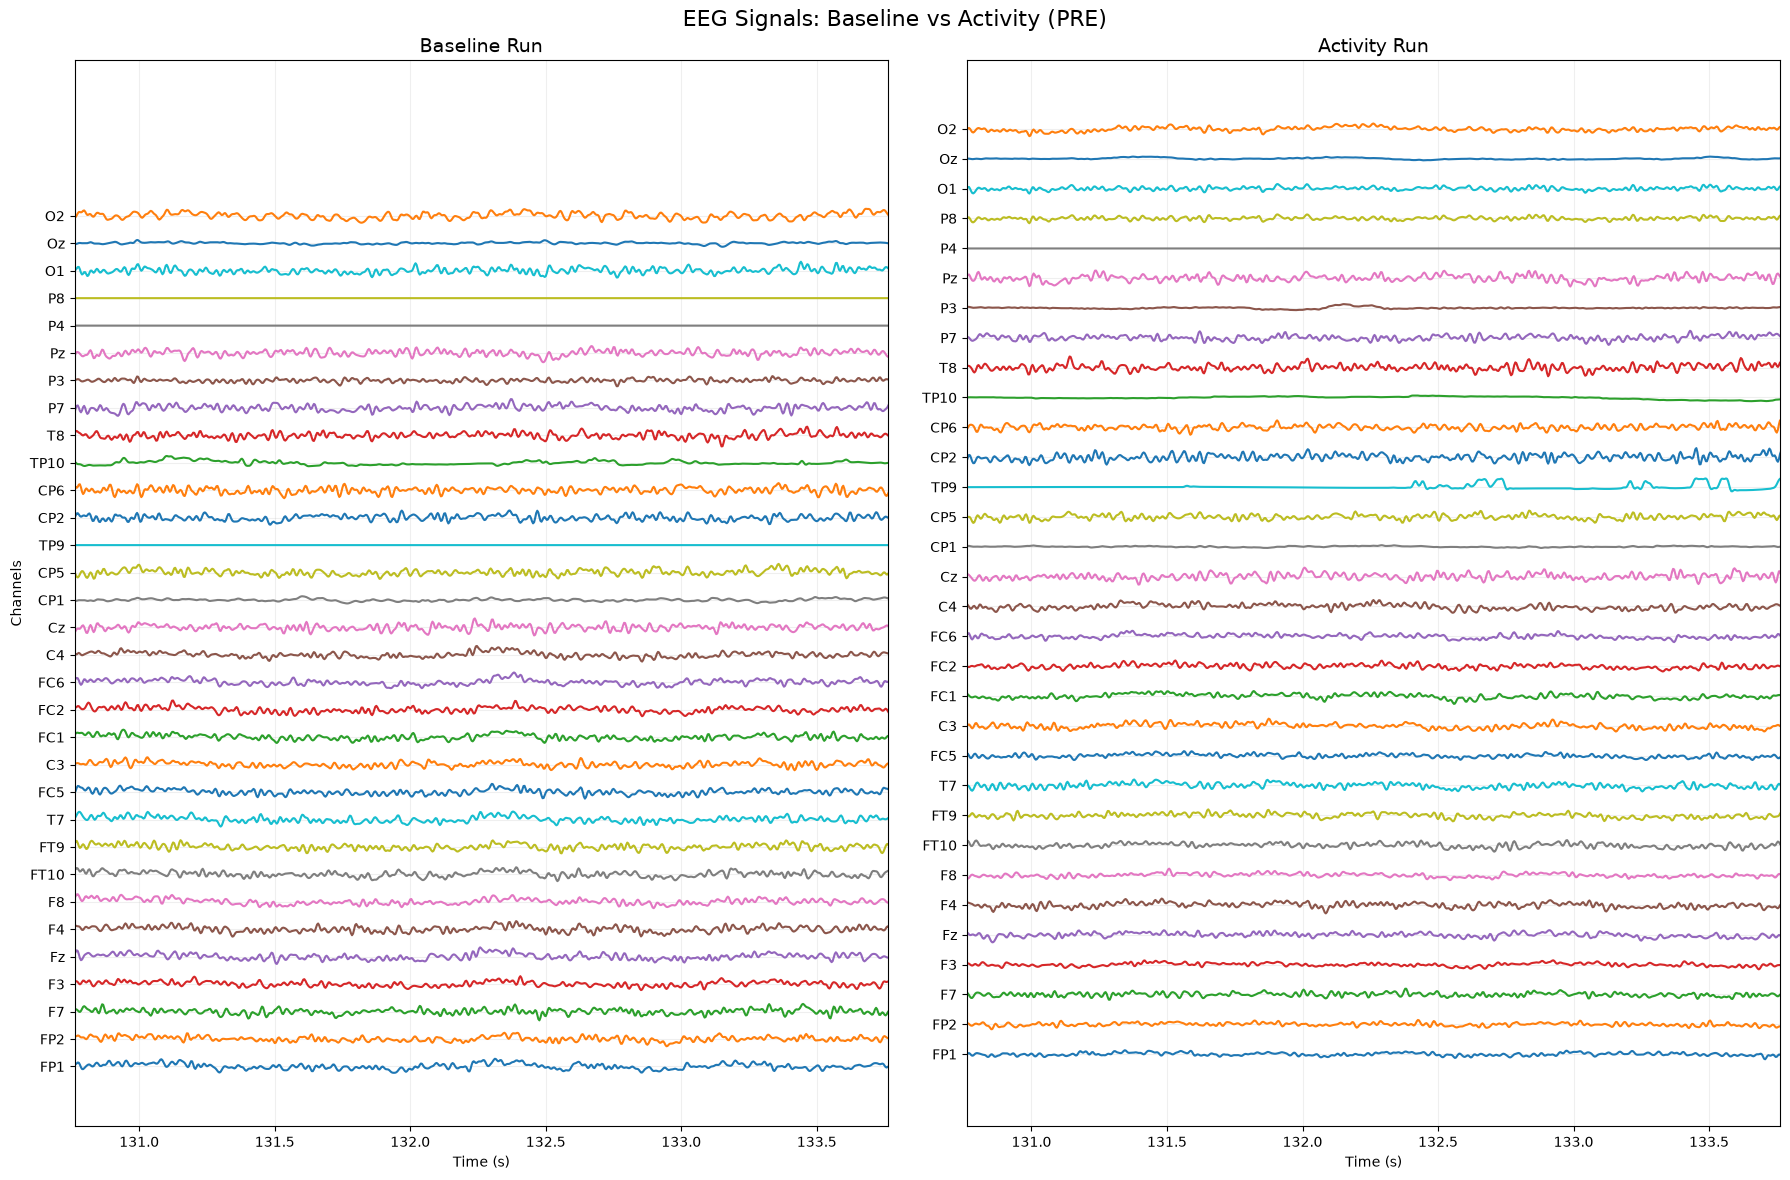

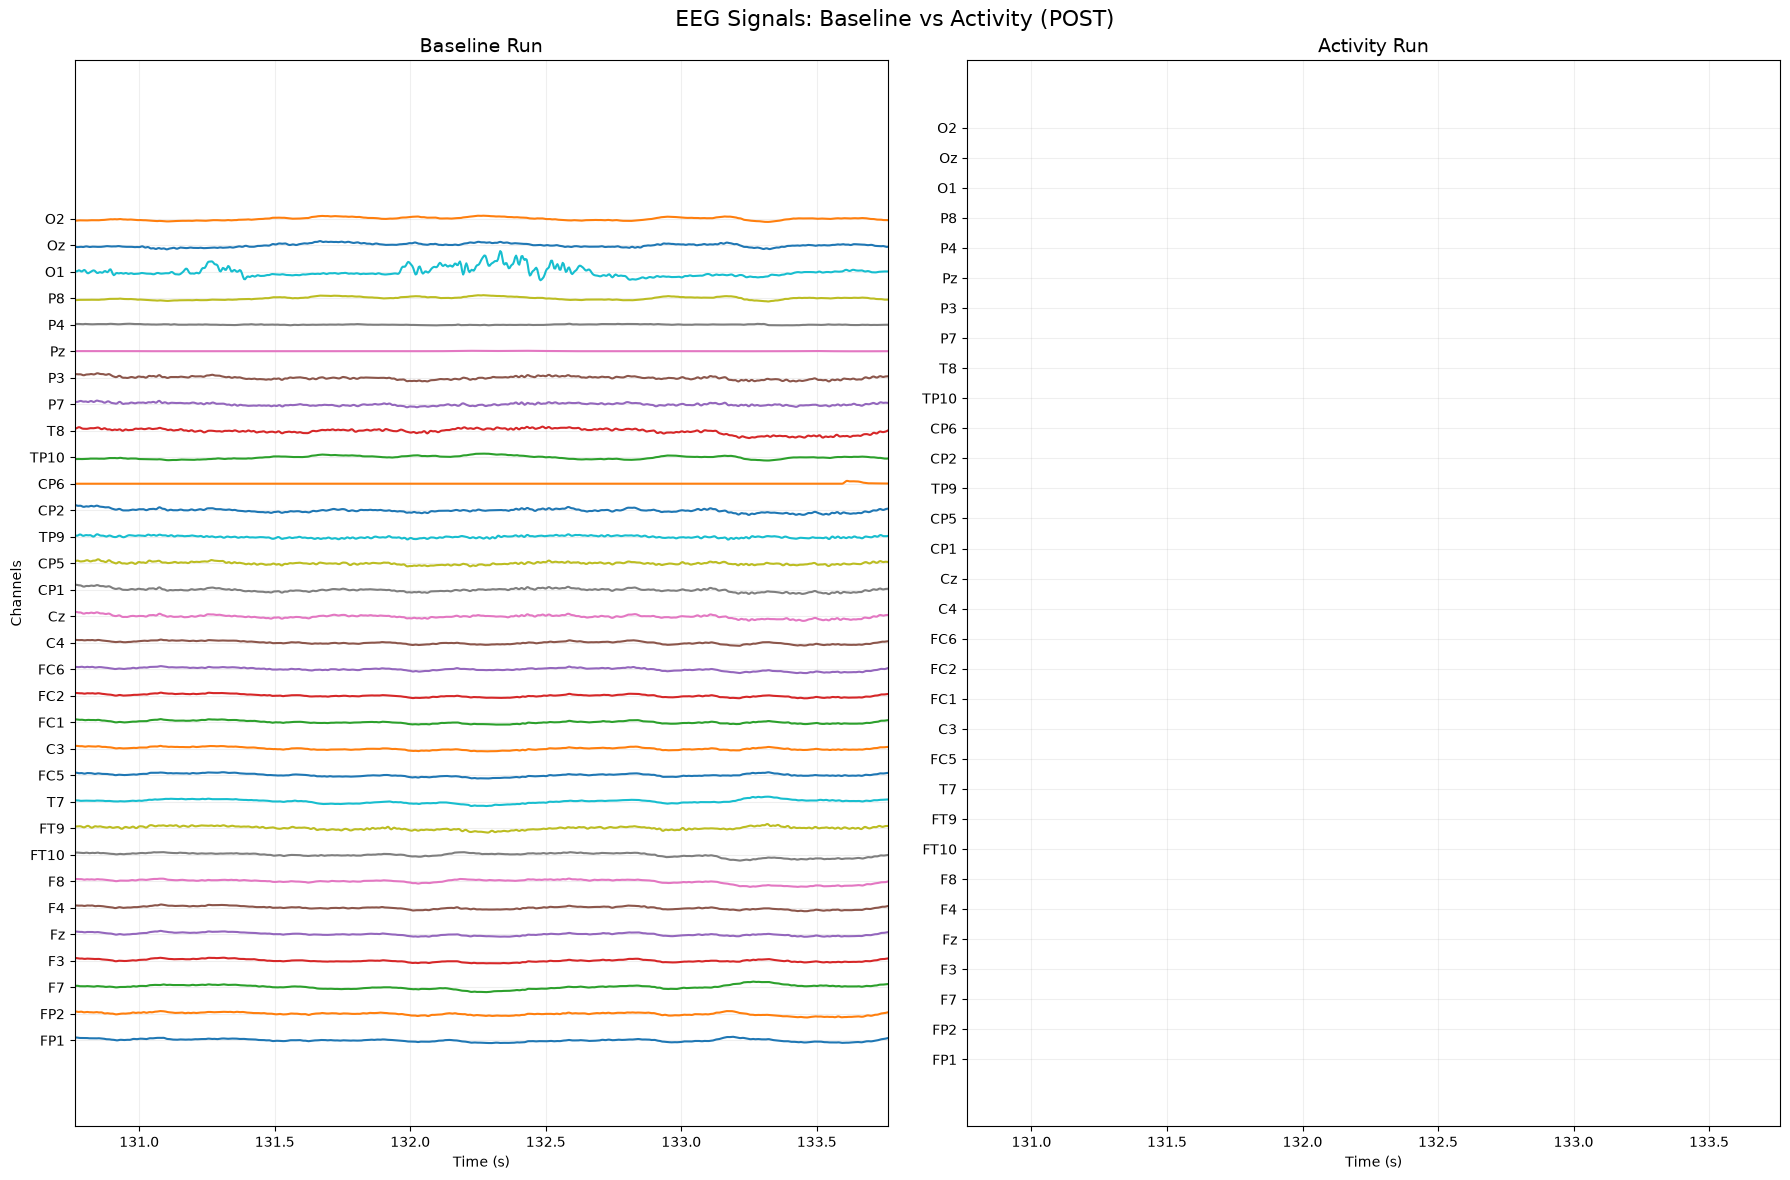

In [70]:
import numpy as np
import matplotlib.pyplot as plt

# Define the recording comparisons
comparisons = [
    ("PRE", raw_clean1, raw_clean2),
    ("POST", raw_clean3, raw_clean4)
]

event_time = 131.2617188 - 0.5
end_time = event_time + 3.0

spacing = 10

for session, baseline_raw, activity_raw in comparisons:

    # Extract EEG data and time vectors
    data1 = baseline_raw.get_data()
    times1 = baseline_raw.times

    data2 = activity_raw.get_data()
    times2 = activity_raw.times

    # Create figure
    fig, axes = plt.subplots(1, 2, figsize=(18, 12))

    # Plot baseline and activity signals
    for i in range(data1.shape[0]):

        signal1 = data1[i]
        signal2 = data2[i]

        # Normalize each channel
        signal1 = (signal1 - np.mean(signal1)) / np.std(signal1)
        signal2 = (signal2 - np.mean(signal2)) / np.std(signal2)

        axes[0].plot(
            times1,
            signal1 + i * spacing,
            linewidth=1.5
        )

        axes[1].plot(
            times2,
            signal2 + i * spacing,
            linewidth=1.5
        )

    # Baseline subplot
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Channels")
    axes[0].set_title("Baseline Run", fontsize=14)

    axes[0].set_yticks(
        np.arange(0, data1.shape[0] * spacing, spacing),
        baseline_raw.ch_names
    )

    axes[0].set_xlim(event_time, end_time)
    axes[0].grid(alpha=0.2)

    # Activity subplot
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel(" ")
    axes[1].set_title("Activity Run", fontsize=14)

    axes[1].set_yticks(
        np.arange(0, data2.shape[0] * spacing, spacing),
        activity_raw.ch_names
    )

    axes[1].set_xlim(event_time, end_time)
    axes[1].grid(alpha=0.2)

    fig.suptitle(
        f"EEG Signals: Baseline vs Activity ({session})",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

## 6. Signal plots — PRE vs POST activity
Existing visualization retained.

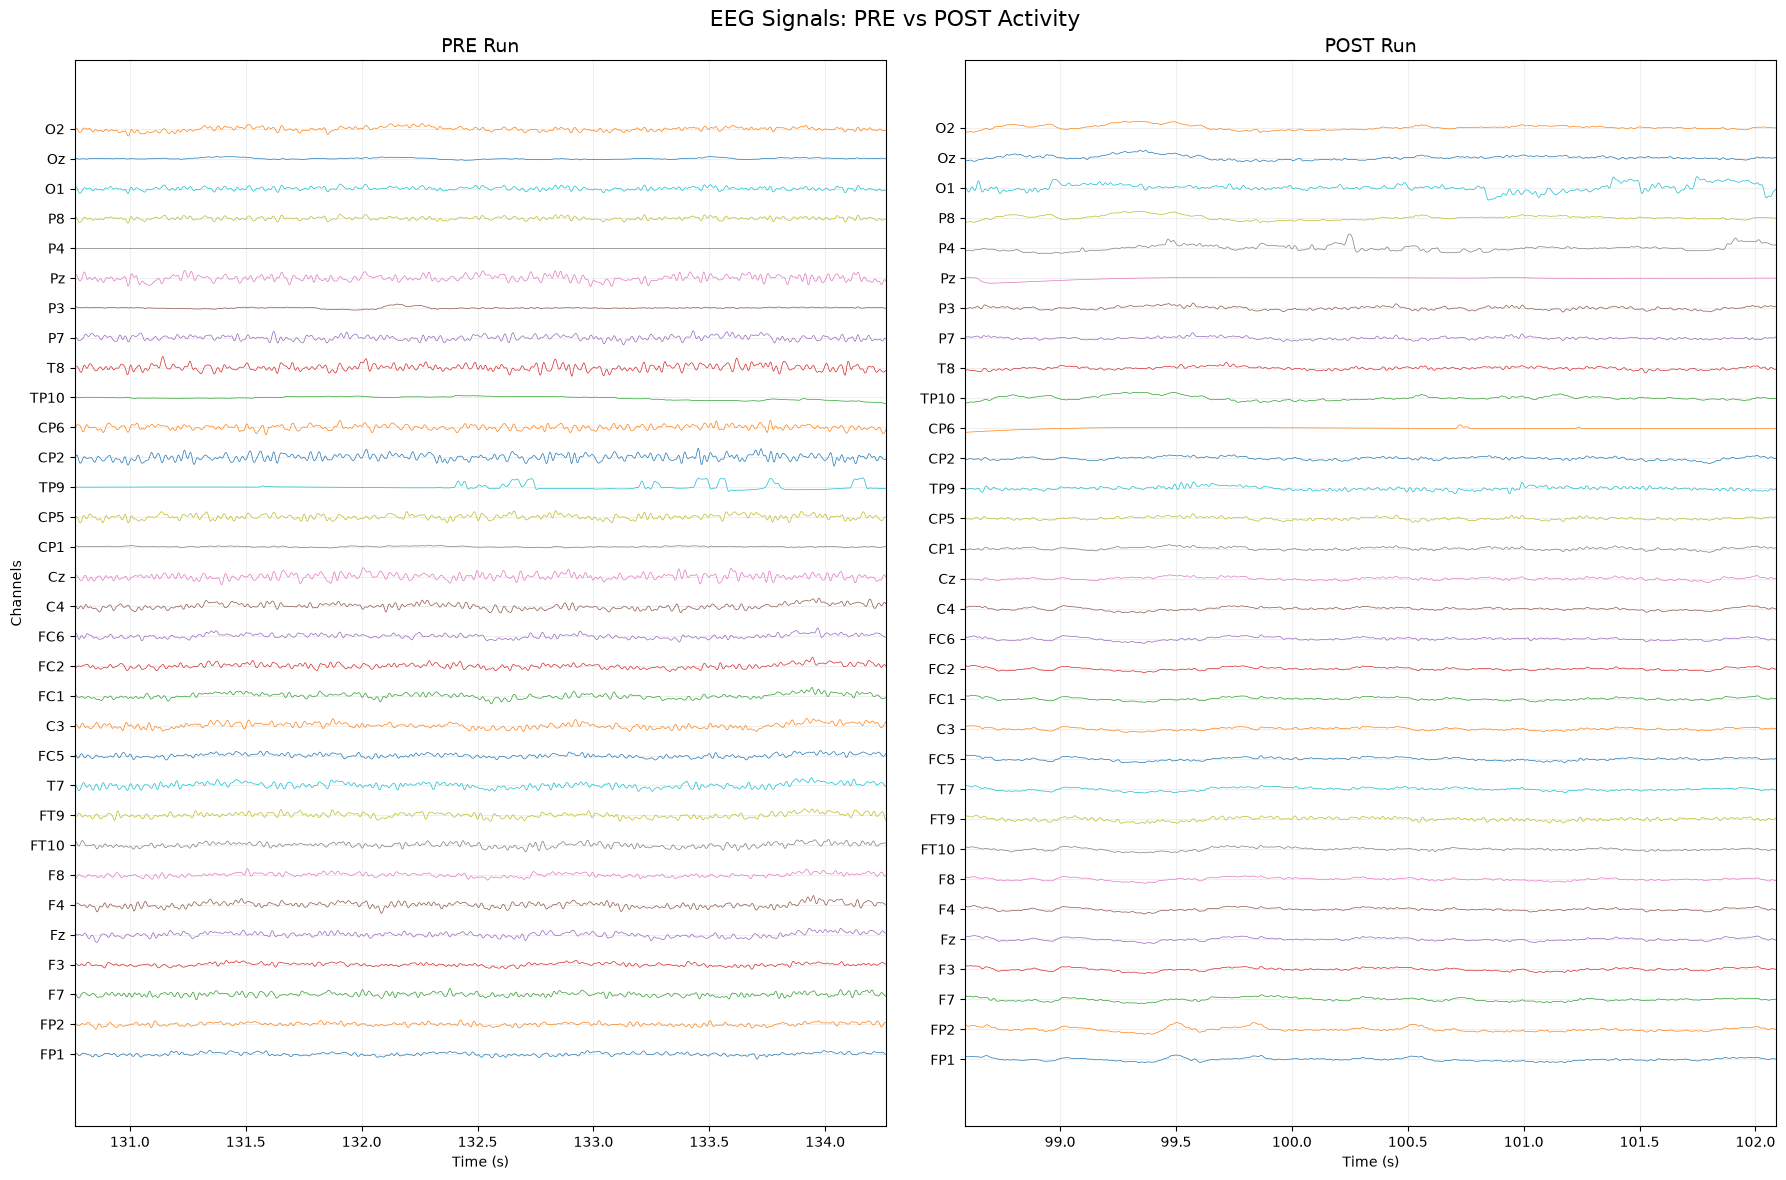

In [71]:
import numpy as np
import matplotlib.pyplot as plt

# Define PRE and POST recordings with their respective event times
comparisons = [
    ("PRE", raw_clean2, 131.2617188),
    ("POST", raw_clean4, 99.08984375)
]

before_time = 0.5
after_time = 3.0
spacing = 10

fig, axes = plt.subplots(1, 2, figsize=(18, 12))

for i, (session, raw, event_time) in enumerate(comparisons):

    # Extract EEG data and time
    data = raw.get_data()
    times = raw.times

    # Plot each channel
    for ch in range(data.shape[0]):

        signal = data[ch]

        # Normalize each channel
        signal = (signal - np.mean(signal)) / np.std(signal)

        axes[i].plot(
            times,
            signal + ch * spacing,
            linewidth=0.5
        )

    # Configure subplot
    axes[i].set_xlabel("Time (s)")
    axes[i].set_ylabel("Channels" if i == 0 else " ")
    axes[i].set_title(f"{session} Run", fontsize=14)

    axes[i].set_yticks(
        np.arange(0, data.shape[0] * spacing, spacing),
        raw.ch_names
    )

    axes[i].set_xlim(
        event_time - before_time,
        event_time + after_time
    )

    axes[i].grid(alpha=0.2)

fig.suptitle("EEG Signals: PRE vs POST Activity", fontsize=16)

plt.tight_layout()
plt.show()

## 7. Signal plots — all four recordings
Existing visualization retained.

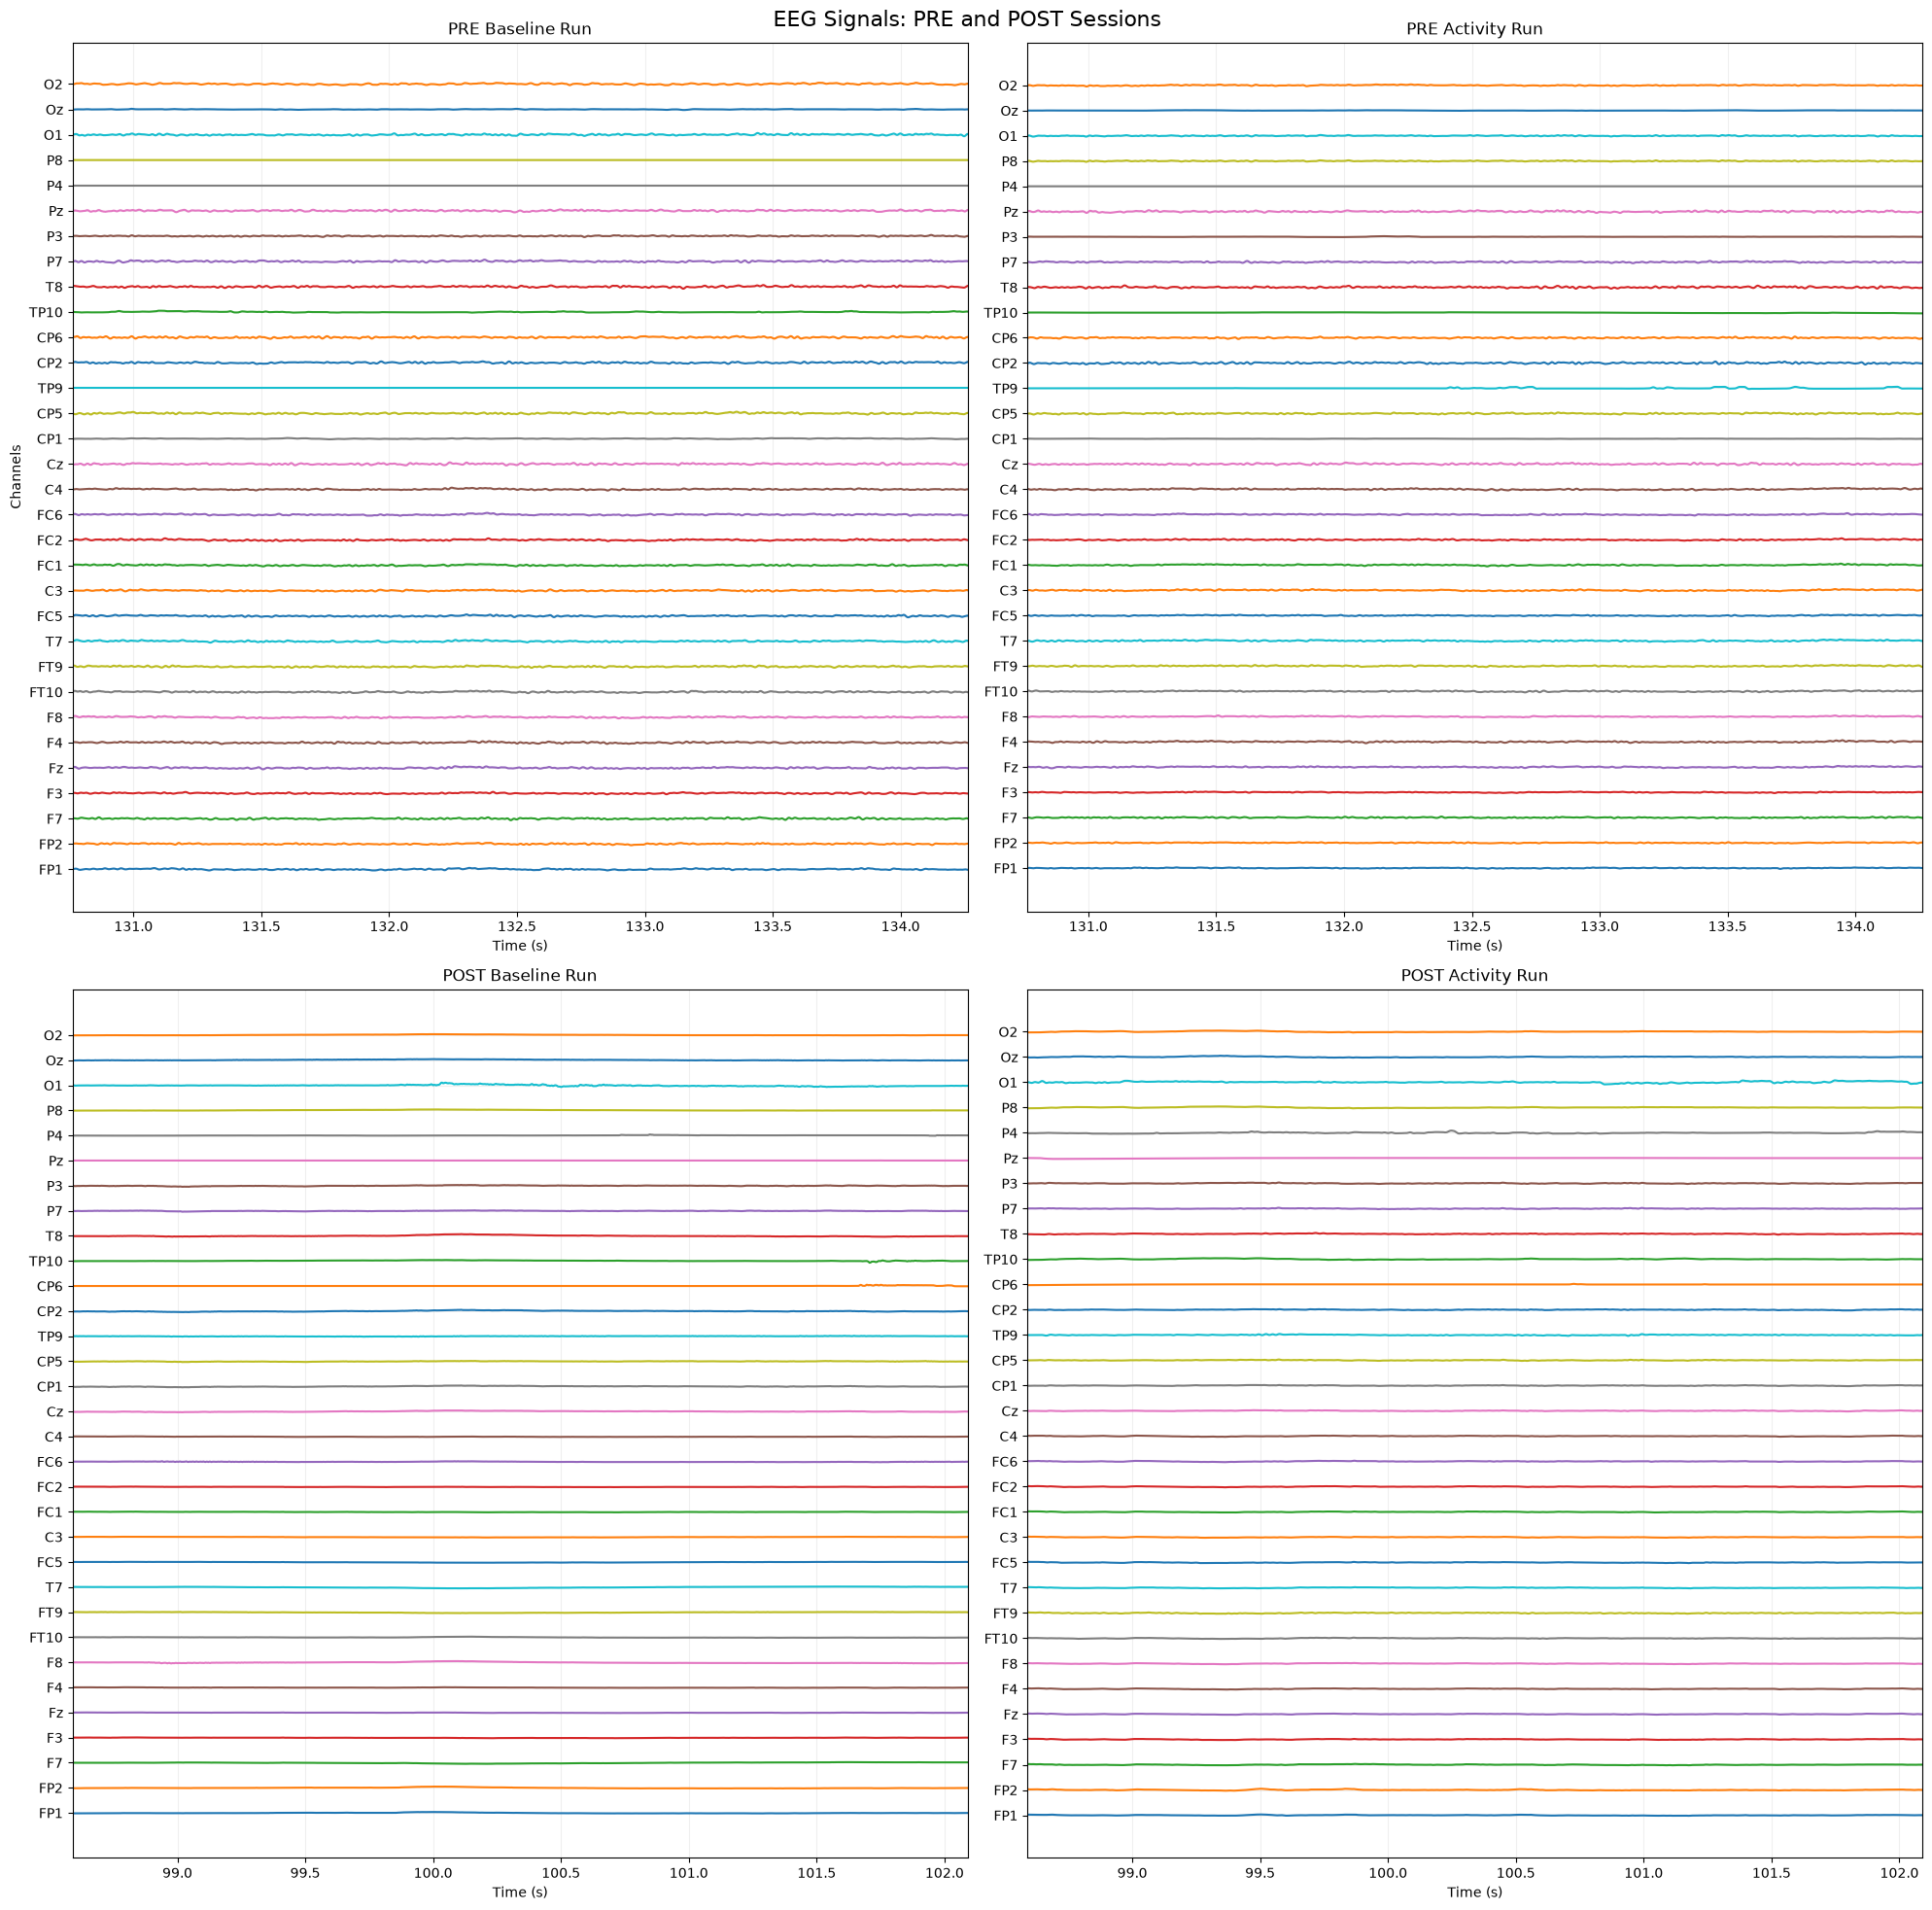

In [72]:
import numpy as np
import matplotlib.pyplot as plt

# Define recordings and their corresponding event times
recordings = [
    ("PRE Baseline Run", raw1, 131.2617188),
    ("PRE Activity Run", raw2, 131.2617188),
    ("POST Baseline Run", raw3, 99.08984375),
    ("POST Activity Run", raw4, 99.08984375)
]

before_time = 0.5
after_time = 3.0
spacing = 50

# Create figure
fig, axes = plt.subplots(2, 2, figsize=(20, 20))
axes = axes.flatten()

for i, (title, raw, event_time) in enumerate(recordings):

    # Extract EEG data and time
    data = raw.get_data()
    times = raw.times

    # Plot each channel
    for ch in range(data.shape[0]):

        signal = data[ch]

        # Normalize each channel
        signal = (signal - np.mean(signal)) / np.std(signal)

        axes[i].plot(
            times,
            signal + ch * spacing,
            linewidth=1.5
        )

    # Configure subplot
    axes[i].set_xlabel("Time (s)")
    axes[i].set_title(title, fontsize=12)

    if i == 0:
        axes[i].set_ylabel("Channels")

    axes[i].set_yticks(
        np.arange(0, data.shape[0] * spacing, spacing),
        raw.ch_names
    )

    axes[i].set_xlim(
        event_time - before_time,
        event_time + after_time
    )

    axes[i].grid(alpha=0.2)

fig.suptitle("EEG Signals: PRE and POST Sessions", fontsize=16)

plt.tight_layout()
plt.show()

## 8. Selected-channel signal inspection
Existing visualization retained.

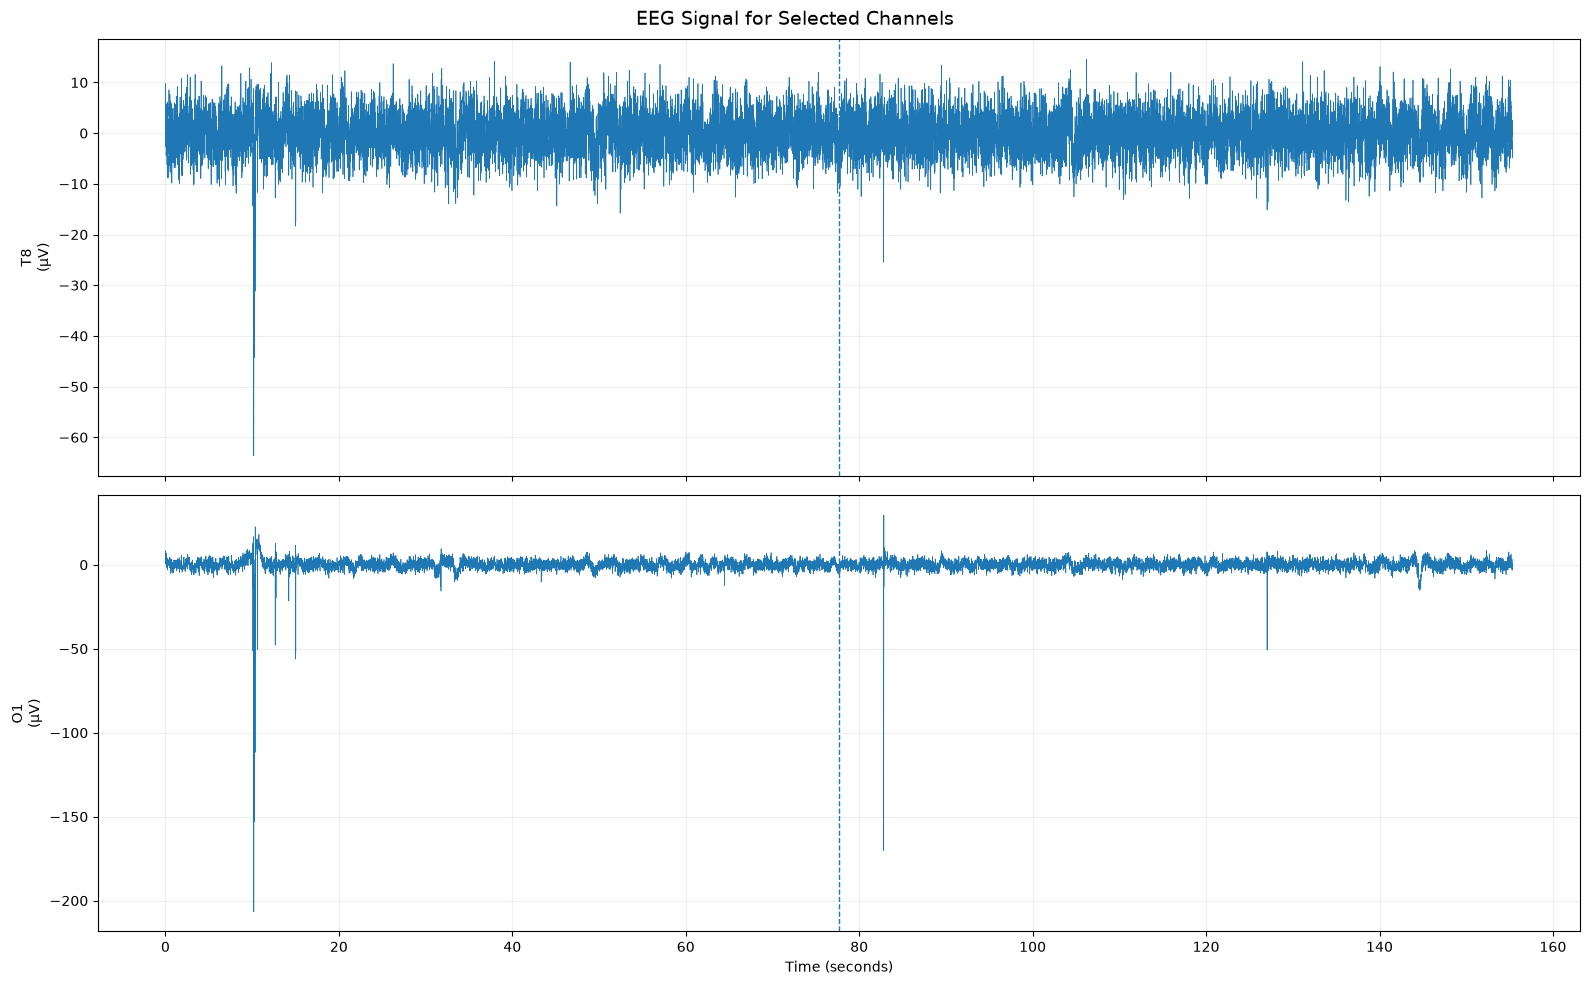

In [73]:
import numpy as np
import matplotlib.pyplot as plt

channels_to_plot = ["T8", "O1"]

# Extract data directly from raw2
data = raw2.get_data()
times = raw2.times

# Check whether selected channels exist
for ch in channels_to_plot:
    if ch not in raw2.ch_names:
        raise ValueError(f"Channel {ch} not found in recording.")

# Create subplots
fig, axes = plt.subplots(
    len(channels_to_plot),
    1,
    figsize=(16, 10),
    sharex=True
)

# Ensure axes is iterable, even for one channel
axes = np.atleast_1d(axes)

for ax, ch in zip(axes, channels_to_plot):

    idx = raw2.ch_names.index(ch)

    ax.plot(
        times,
        data[idx] * 1e6,
        linewidth=0.5
    )

    ax.axvline(
        times[-1] / 2,
        linestyle="--",
        linewidth=1
    )

    ax.set_ylabel(f"{ch}\n(µV)")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    "EEG Signal for Selected Channels",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 9. PSD — baseline vs activity
Existing visualization retained.

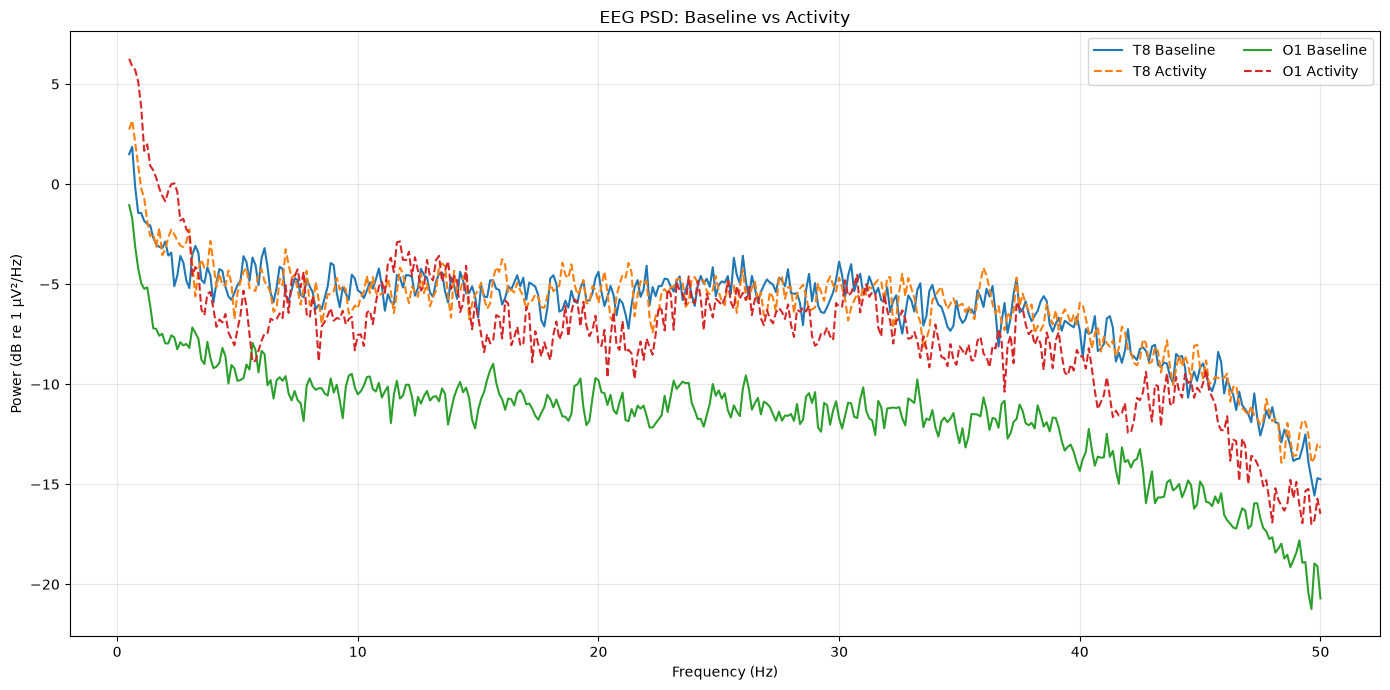

In [74]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Select the channels you want to compare
selected_channels = ["T8" , "O1"]

def get_psd(raw, channel):
    idx = raw.ch_names.index(channel)
    eeg_uv = raw.get_data(picks=[idx])[0] * 1e6
    sfreq = raw.info["sfreq"]

    freqs, psd = welch(
        eeg_uv,
        fs=sfreq,
        nperseg=2048,
        noverlap=1024
    )

    mask = (freqs >= 0.5) & (freqs <= 50)

    psd_db = 10 * np.log10(psd[mask] + 1e-20)

    return freqs[mask], psd_db


plt.figure(figsize=(14, 7))

for ch in selected_channels:
    freqs, baseline_psd = get_psd(raw_clean1, ch)
    _, activity_psd = get_psd(raw_clean2, ch)

    plt.plot(
        freqs, baseline_psd,
        linestyle="-",
        label=f"{ch} Baseline"
    )

    plt.plot(
        freqs, activity_psd,
        linestyle="--",
        label=f"{ch} Activity"
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB re 1 µV²/Hz)")
plt.title("EEG PSD: Baseline vs Activity")
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. PSD — O1 baseline vs activity
Existing visualization retained.

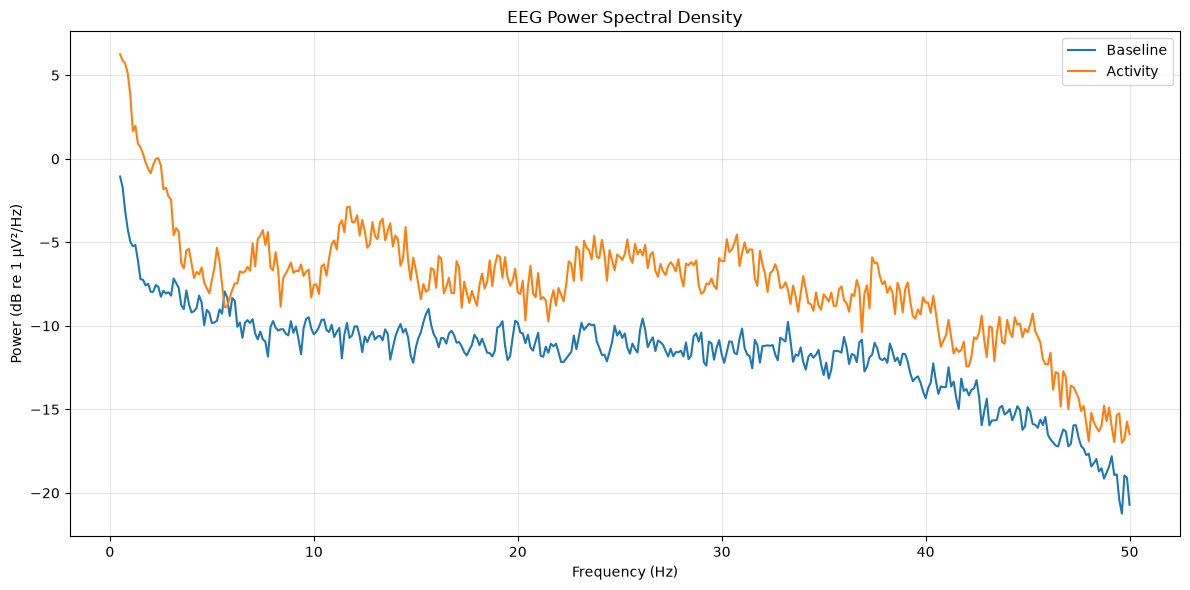

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

channel = "O1"

def get_psd(raw, channel):
    idx = raw.ch_names.index(channel)

    # Convert EEG from volts to microvolts
    eeg_uv = raw.get_data(picks=[idx])[0] * 1e6
    sfreq = raw.info["sfreq"]

    freqs, psd = welch(
        eeg_uv,
        fs=sfreq,
        nperseg=2048,
        noverlap=1024
    )

    mask = (freqs >= 0.5) & (freqs <= 50)

    return freqs[mask], 10 * np.log10(psd[mask] + 1e-20)


# Baseline and activity
freqs, baseline_psd = get_psd(raw_clean1, channel)
_, activity_psd = get_psd(raw_clean2, channel)  # Change variable if needed

plt.figure(figsize=(12, 6))

plt.plot(freqs, baseline_psd, label="Baseline", linewidth=1.5)
plt.plot(freqs, activity_psd, label="Activity", linewidth=1.5)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB re 1 µV²/Hz)")
plt.title(f"EEG Power Spectral Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Event-window PSD — baseline vs activity
The event timestamp is now explicitly taken from the PRE configuration instead of relying on a variable left over from a previous notebook execution.

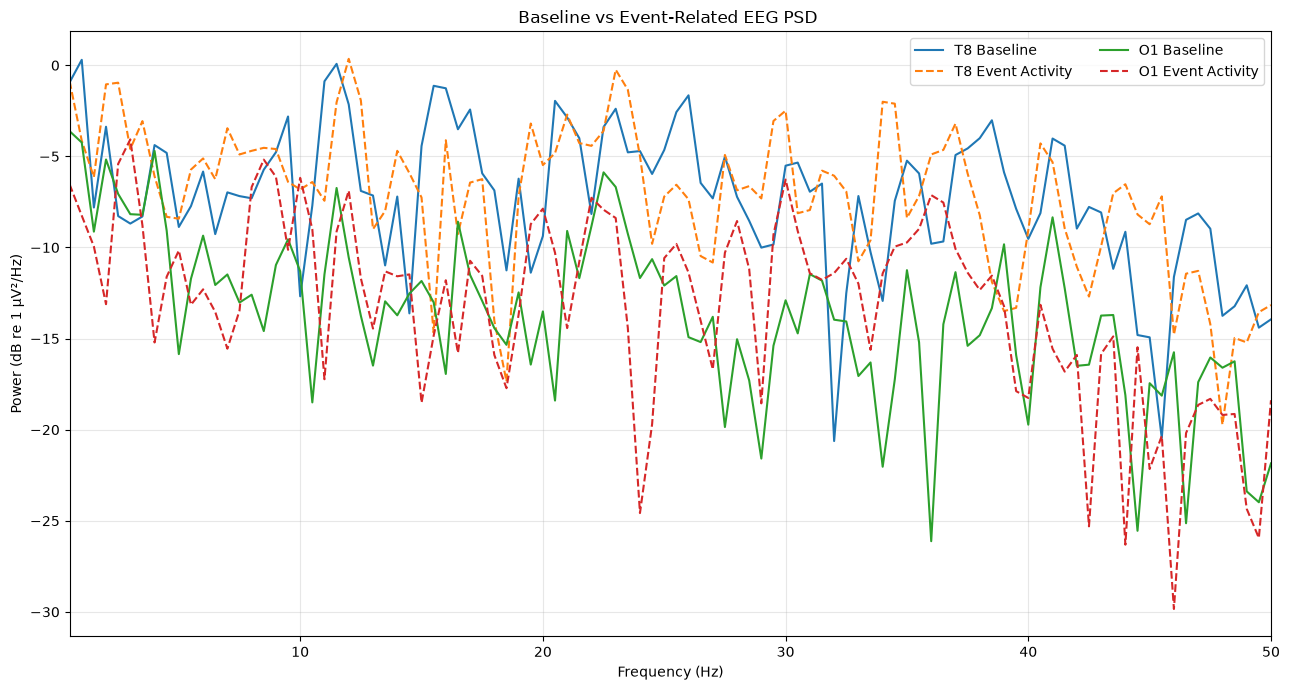

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# ---------- SETTINGS ----------
baseline_raw = raw_clean1
activity_raw = raw_clean2  # Change to your activity variable

selected_channels = ["T8" , "O1"]

pre_event = 0.5     # Seconds before event
post_event = 3.0    # Seconds after event

# ---------- PSD FUNCTION ----------
def calculate_segment_psd(raw, channel, start_time, end_time):

    sfreq = raw.info["sfreq"]
    idx = raw.ch_names.index(channel)

    start_sample = int(start_time * sfreq)
    end_sample = int(end_time * sfreq)

    # Extract only the selected time segment
    eeg_uv = raw.get_data(
        picks=[idx],
        start=start_sample,
        stop=end_sample
    )[0] * 1e6

    if len(eeg_uv) < 32:
        raise ValueError("Segment is too short for a reliable PSD estimate.")

    nperseg = min(512, len(eeg_uv))

    freqs, psd = welch(
        eeg_uv,
        fs=sfreq,
        nperseg=nperseg,
        noverlap=nperseg // 2
    )

    # Convert power to dB re 1 µV²/Hz
    psd_db = 10 * np.log10(psd + 1e-20)

    mask = (freqs >= 0.5) & (freqs <= 50)

    return freqs[mask], psd_db[mask]


# ---------- EXTRACT EVENT WINDOW ----------
event_time = EVENT_TIMES['PRE']
start_time = event_time - pre_event
end_time = event_time + post_event

if start_time < 0 or end_time > activity_raw.times[-1]:
    raise ValueError("Event window extends beyond the activity recording.")

# ---------- PLOT ----------
plt.figure(figsize=(13, 7))

for ch in selected_channels:

    # Baseline: same duration as the event window
    base_freqs, base_psd = calculate_segment_psd(
        baseline_raw,
        ch,
        0,
        pre_event + post_event
    )

    # Activity: around the event timestamp
    act_freqs, act_psd = calculate_segment_psd(
        activity_raw,
        ch,
        start_time,
        end_time
    )

    plt.plot(
        base_freqs, base_psd,
        linestyle="-",
        label=f"{ch} Baseline"
    )

    plt.plot(
        act_freqs, act_psd,
        linestyle="--",
        label=f"{ch} Event Activity"
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB re 1 µV²/Hz)")
plt.title("Baseline vs Event-Related EEG PSD ")
plt.xlim(0.5, 50)
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Overall PSD — PRE vs POST activity
Corrected the POST input to `POST_Activity` (run-2), rather than `POST_Baseline` (run-1).

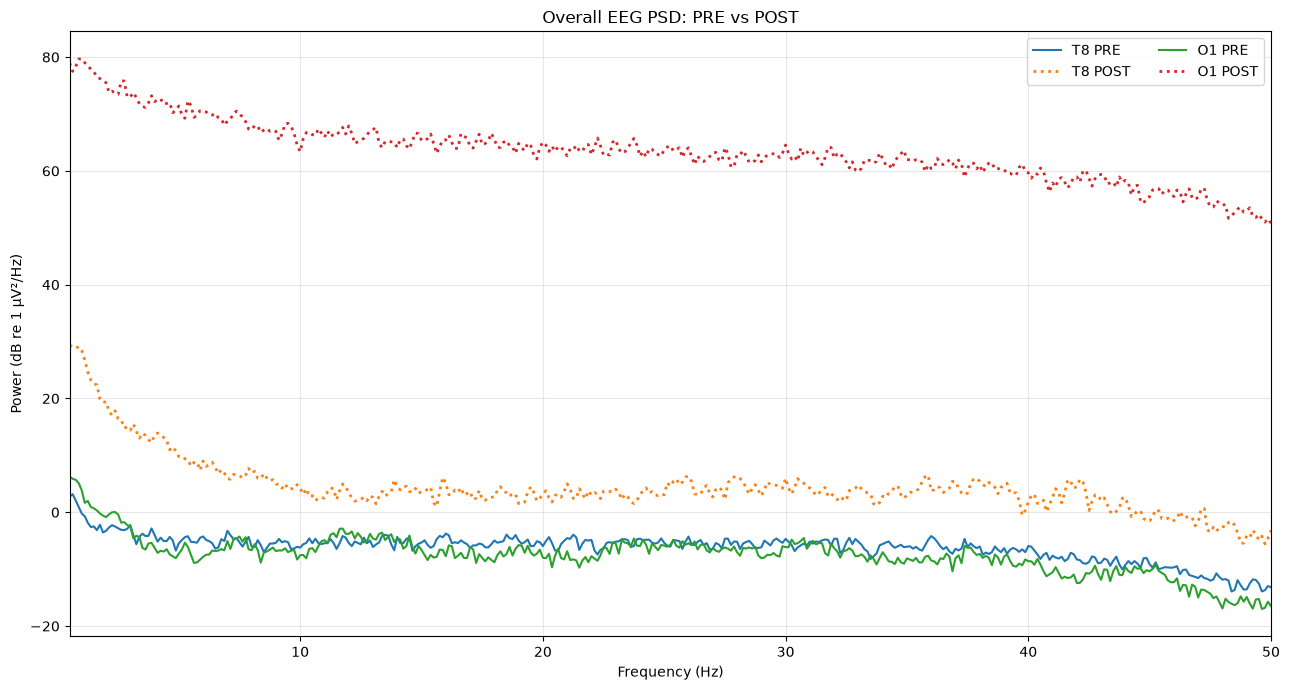

In [77]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

pre_raw = raw_clean2
post_raw = raw_clean4

channels = ["T8" , "O1"]

def calculate_psd(raw, channel):
    sfreq = raw.info["sfreq"]
    signal_uv = raw.get_data(picks=[channel])[0] * 1e6

    nperseg = min(2048, len(signal_uv))

    freqs, power = welch(
        signal_uv,
        fs=sfreq,
        nperseg=nperseg,
        noverlap=nperseg // 2
    )

    mask = (freqs >= 0.5) & (freqs <= 50)

    power_db = 10 * np.log10(power[mask] + 1e-20)
    return freqs[mask], power_db


plt.figure(figsize=(13, 7))

for channel in channels:
    f_pre, p_pre = calculate_psd(pre_raw, channel)
    f_post, p_post = calculate_psd(post_raw, channel)

    # PRE: solid line
    plt.plot(
        f_pre, p_pre,
        linestyle="-",
        label=f"{channel} PRE"
    )

    # POST: dotted line
    plt.plot(
        f_post, p_post,
        linestyle=":",
        linewidth=2,
        label=f"{channel} POST"
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB re 1 µV²/Hz)")
plt.title("Overall EEG PSD: PRE vs POST")
plt.xlim(0.5, 50)
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

## 13. Event-related PSD — PRE vs POST activity
Uses the activity recordings for both sessions. The timestamps remain provisional until validated against the event markers and event-code documentation.

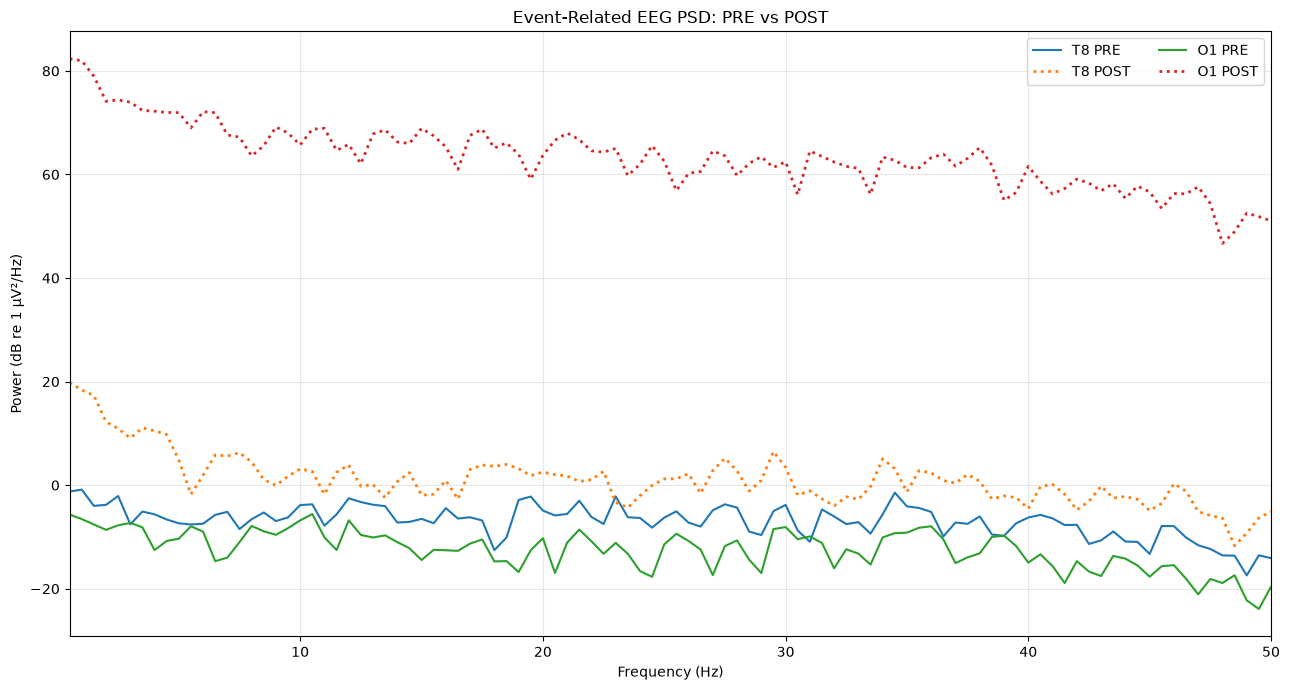

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

pre_raw = raw_clean2
post_raw = raw_clean4

channels = ["T8" , "O1"]

pre_event_time = 131.2617188
post_event_time = 99.08984375

# Window relative to each event
before_event = 2.0
after_event = 3.0


def calculate_event_psd(raw, channel, event_time):
    sfreq = raw.info["sfreq"]

    start_time = event_time - before_event
    end_time = event_time + after_event

    if start_time < 0 or end_time > raw.times[-1]:
        raise ValueError(
            f"Event window exceeds recording for {channel}."
        )

    start_sample = int(start_time * sfreq)
    end_sample = int(end_time * sfreq)

    signal_uv = (
        raw.get_data(
            picks=[channel],
            start=start_sample,
            stop=end_sample
        )[0] * 1e6
    )

    nperseg = min(512, len(signal_uv))

    freqs, power = welch(
        signal_uv,
        fs=sfreq,
        nperseg=nperseg,
        noverlap=nperseg // 2
    )

    mask = (freqs >= 0.5) & (freqs <= 50)

    return freqs[mask], 10 * np.log10(power[mask] + 1e-20)


plt.figure(figsize=(13, 7))

for channel in channels:
    f_pre, p_pre = calculate_event_psd(
        pre_raw, channel, pre_event_time
    )

    f_post, p_post = calculate_event_psd(
        post_raw, channel, post_event_time
    )

    # PRE: solid line
    plt.plot(
        f_pre, p_pre,
        linestyle="-",
        label=f"{channel} PRE"
    )

    # POST: dotted line
    plt.plot(
        f_post, p_post,
        linestyle=":",
        linewidth=2,
        label=f"{channel} POST"
    )

plt.xlabel("Frequency (Hz)")
plt.ylabel("Power (dB re 1 µV²/Hz)")
plt.title("Event-Related EEG PSD: PRE vs POST")
plt.xlim(0.5, 50)
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

## 14. Relative band-power plot
The original plot structure is retained, but the mislabeled 0.5–4 Hz range is correctly identified as **delta**, not alpha.

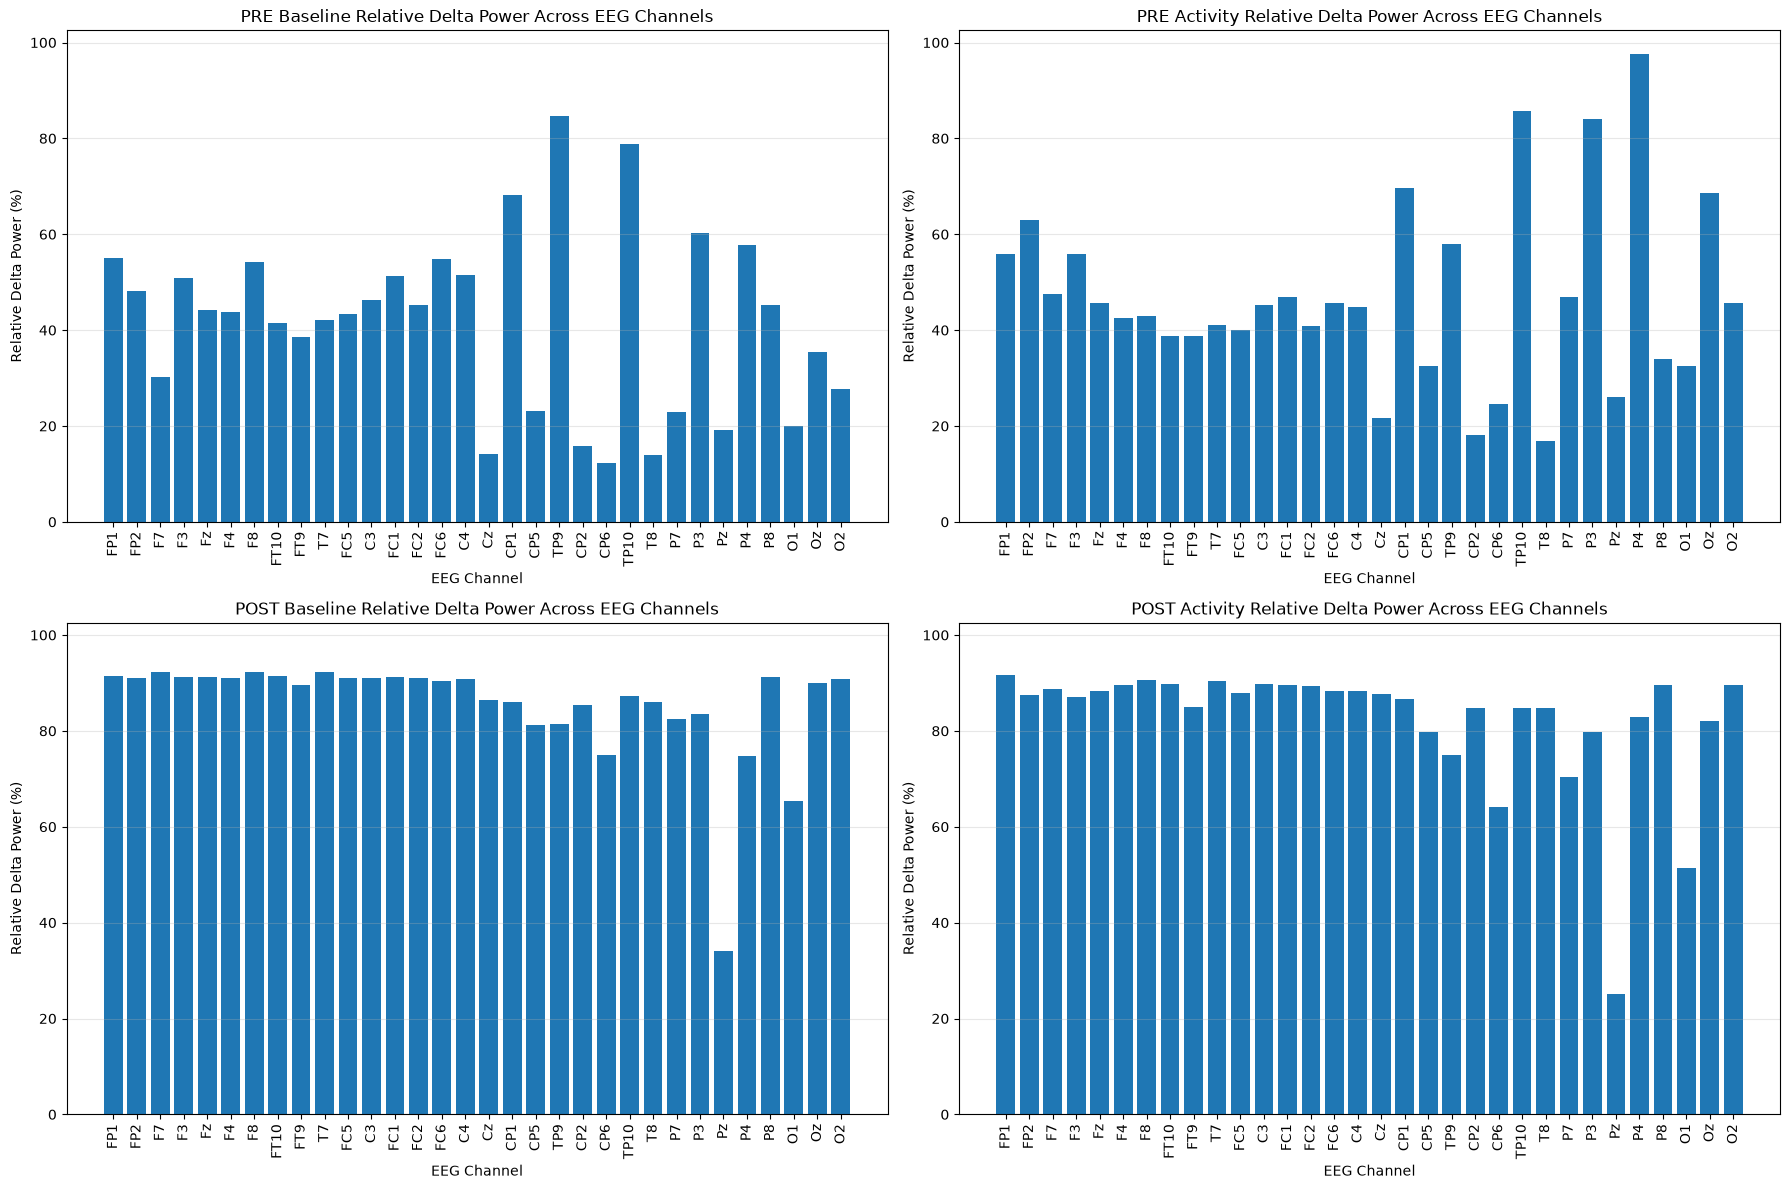

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Store recordings
recordings = {
    "PRE Baseline": raw1,
    "PRE Activity": raw2,
    "POST Baseline": raw3,
    "POST Activity": raw4
}

# Channel names
channel_names = raw1.ch_names

# Frequency ranges
delta_range = (0.5, 4)
total_range = (0.5, 50)

# Store relative power for all recordings
relative_power = {}

# Calculate relative power
for name, raw in recordings.items():

    sfreq = raw.info["sfreq"]
    relative_values = []

    for channel in channel_names:

        # Extract signal in microvolts
        signal_uv = raw.get_data(picks=[channel])[0] * 1e6

        # Calculate PSD
        nperseg = min(2048, len(signal_uv))

        freqs, psd = welch(
            signal_uv,
            fs=sfreq,
            nperseg=nperseg
        )

        # Frequency masks
        delta_mask = (
            (freqs >= delta_range[0]) &
            (freqs <= delta_range[1])
        )

        total_mask = (
            (freqs >= total_range[0]) &
            (freqs <= total_range[1])
        )

        # Integrate PSD
        delta_power = np.trapezoid(
            psd[delta_mask],
            freqs[delta_mask]
        )

        total_power = np.trapezoid(
            psd[total_mask],
            freqs[total_mask]
        )

        # Relative power
        relative_delta = (
            delta_power / total_power * 100
            if total_power > 0 else np.nan
        )

        relative_values.append(relative_delta)

    relative_power[name] = relative_values


# Find common maximum for all plots
max_power = max(
    np.nanmax(values)
    for values in relative_power.values()
)

# Plot
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for i, (name, values) in enumerate(relative_power.items()):

    axes[i].bar(channel_names, values)

    axes[i].set_xlabel("EEG Channel")
    axes[i].set_ylabel("Relative Delta Power (%)")
    axes[i].set_title(f"{name} Relative Delta Power Across EEG Channels")

    axes[i].tick_params(axis="x", rotation=90)
    axes[i].grid(axis="y", alpha=0.3)
    axes[i].set_ylim(0, max_power + 5)

plt.tight_layout()
plt.show()

## 15. Gamma-band power plot — PRE baseline
Existing visualization retained.

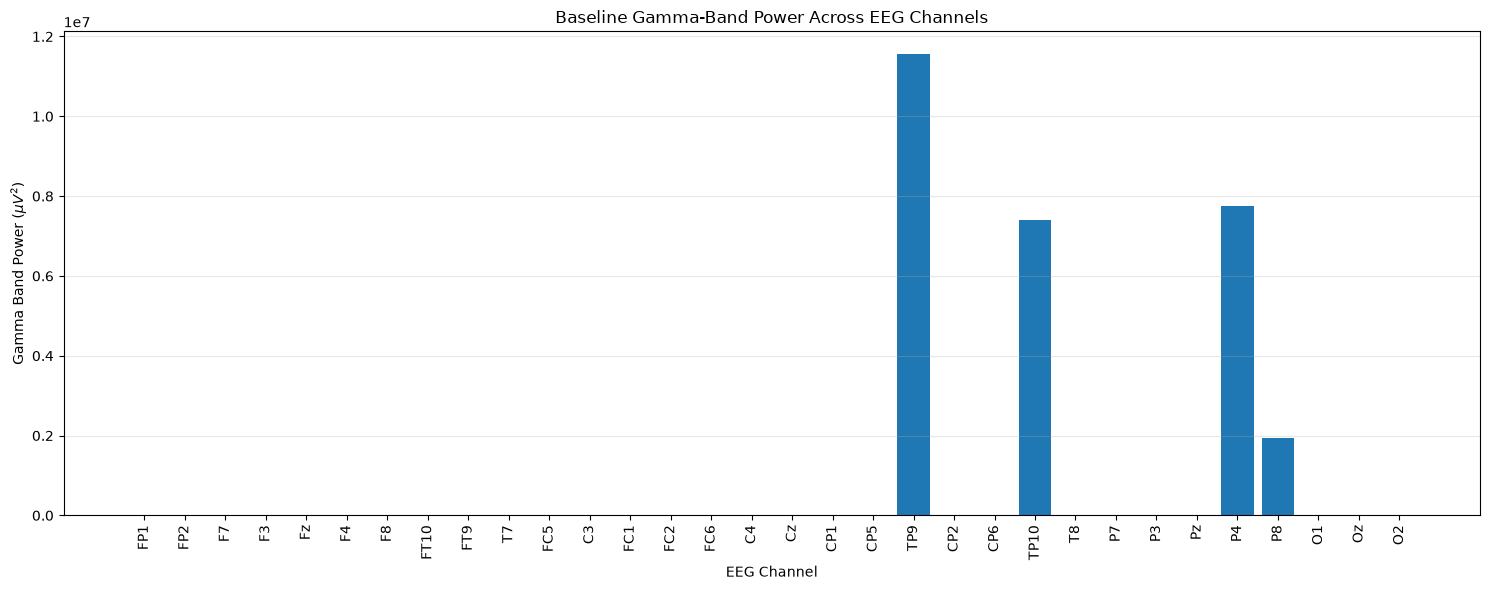

In [80]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# Baseline recording
baseline_raw = raw1

sfreq = baseline_raw.info["sfreq"]
channel_names = baseline_raw.ch_names

gamma_power = []

for channel in channel_names:
    # Get the complete channel signal in microvolts
    signal_uv = baseline_raw.get_data(
        picks=[channel]
    )[0] * 1e6

    # Calculate power spectral density
    nperseg = min(2048, len(signal_uv))

    freqs, psd = welch(
        signal_uv,
        fs=sfreq,
        nperseg=nperseg
    )

    # Select gamma band: 30–50 Hz
    gamma_mask = (freqs >= 30) & (freqs <= 50)

    # Integrate PSD to obtain gamma-band power
    power = np.trapezoid(
        psd[gamma_mask],
        freqs[gamma_mask]
    )

    gamma_power.append(power)

# Bar plot
plt.figure(figsize=(15, 6))

plt.bar(channel_names, gamma_power)

plt.xlabel("EEG Channel")
plt.ylabel(r"Gamma Band Power ($\mu V^2$)")
plt.title("Baseline Gamma-Band Power Across EEG Channels")

plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 16. Extract absolute and relative power for all five frequency bands
This is the structured analysis output used by the master CSV. Each row represents one subject × recording × channel × frequency band. Power is integrated from Welch PSD in µV²; relative power is the band power divided by total 0.5–50 Hz power.

In [81]:
FREQUENCY_BANDS = {
    "delta": (0.5, 4.0),
    "theta": (4.0, 8.0),
    "alpha": (8.0, 13.0),
    "beta": (13.0, 30.0),
    "gamma": (30.0, 50.0),
}
TOTAL_POWER_RANGE = (0.5, 50.0)

def integrate_psd(freqs, psd, low, high):
    mask = (freqs >= low) & (freqs <= high)
    if mask.sum() < 2:
        return np.nan
    return float(np.trapezoid(psd[mask], freqs[mask]))

def calculate_channel_band_powers(raw, channel):
    signal_uv = raw.get_data(picks=[channel])[0] * 1e6
    sfreq = float(raw.info["sfreq"])
    nperseg = min(2048, len(signal_uv))

    freqs, psd = welch(
        signal_uv,
        fs=sfreq,
        nperseg=nperseg,
        noverlap=nperseg // 2
    )

    total_power = integrate_psd(
        freqs, psd, *TOTAL_POWER_RANGE
    )

    results = {}
    for band, (low, high) in FREQUENCY_BANDS.items():
        band_power = integrate_psd(freqs, psd, low, high)
        relative_power = (
            band_power / total_power * 100
            if np.isfinite(total_power) and total_power > 0
            else np.nan
        )

        results[band] = {
            "frequency_min": low,
            "frequency_max": high,
            "absolute_power": band_power,
            "relative_power": relative_power,
        }

    return results


result_rows = []

for recording_name, raw in raw_clean_files.items():
    session, run = RECORDINGS[recording_name]
    metadata = recording_metadata[recording_name]
    condition = "Baseline" if run == 1 else "Activity"

    for channel in raw.ch_names:
        channel_results = calculate_channel_band_powers(raw, channel)

        for band, values in channel_results.items():
            result_rows.append({
                "subject_id": SUBJECT_ID,
                "session": session,
                "run": run,
                "condition": condition,
                "sampling_frequency": float(raw.info["sfreq"]),
                "duration": float(raw.times[-1]),
                "channel_count": len(raw.ch_names),
                "sample_count": raw.n_times,
                "channel": channel,
                "band": band,
                "frequency_min": values["frequency_min"],
                "frequency_max": values["frequency_max"],
                "absolute_power": values["absolute_power"],
                "relative_power": values["relative_power"],
                "event_id": "",
                "event_onset": np.nan,
                "event_duration": np.nan,
                "event_code": "",
            })

subject_results_df = pd.DataFrame(result_rows)
print("Rows generated:", len(subject_results_df))
print("Expected rows:", sum(len(r.ch_names) for r in raw_clean_files.values()) * len(FREQUENCY_BANDS))
display(subject_results_df.head(10))

Rows generated: 640
Expected rows: 640


,subject_id,session,run,condition,sampling_frequency,duration,channel_count,sample_count,channel,band,frequency_min,frequency_max,absolute_power,relative_power,event_id,event_onset,event_duration,event_code
0,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,delta,0.5,4.0,5.966074,55.101996,,NaN,NaN,
1,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,theta,4.0,8.0,0.870299,8.037986,,NaN,NaN,
2,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,alpha,8.0,13.0,0.668248,6.171864,,NaN,NaN,
3,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,beta,13.0,30.0,1.991549,18.393722,,NaN,NaN,
4,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP1,gamma,30.0,50.0,1.331158,12.294432,,NaN,NaN,
5,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,delta,0.5,4.0,5.002496,48.142722,,NaN,NaN,
6,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,theta,4.0,8.0,0.712753,6.859347,,NaN,NaN,
7,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,alpha,8.0,13.0,0.697779,6.715242,,NaN,NaN,
8,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,beta,13.0,30.0,2.359082,22.703193,,NaN,NaN,
9,Re01,ses-1,1,Baseline,256.0,179.996094,32,46080,FP2,gamma,30.0,50.0,1.618861,15.579497,,NaN,NaN,


## 17. Replace this subject's rows in the master CSV
The master file is cumulative across subjects. On each successful run, all previous rows for the selected subject are replaced with the newly generated rows. Other subjects are preserved. A temporary file is written first and then atomically moved into place.

In [82]:
CSV_COLUMNS = [
    "subject_id", "session", "run", "condition",
    "sampling_frequency", "duration", "channel_count", "sample_count",
    "channel", "band", "frequency_min", "frequency_max",
    "absolute_power", "relative_power",
    "event_id", "event_onset", "event_duration", "event_code"
]

UNIQUE_KEYS = [
    "subject_id", "session", "run", "channel", "band", "event_id"
]

def save_subject_results(new_data):
    if new_data is None or new_data.empty:
        raise ValueError(
            "No subject results were generated. Existing CSV was not changed."
        )

    new_data = new_data.copy()
    new_data["subject_id"] = SUBJECT_ID

    for column in CSV_COLUMNS:
        if column not in new_data.columns:
            new_data[column] = np.nan
    new_data = new_data[CSV_COLUMNS]

    if CSV_FILE.exists():
        existing = pd.read_csv(CSV_FILE)
        for column in CSV_COLUMNS:
            if column not in existing.columns:
                existing[column] = np.nan
        existing = existing[CSV_COLUMNS]
        existing["subject_id"] = (
            existing["subject_id"].astype(str)
            .str.replace("sub-", "", regex=False)
        )
        # Remove only the currently selected subject.
        existing = existing[existing["subject_id"] != SUBJECT_ID]
    else:
        existing = pd.DataFrame(columns=CSV_COLUMNS)

    combined = pd.concat([existing, new_data], ignore_index=True)

    # Normalize empty event identifiers so duplicate checks are stable.
    combined["event_id"] = combined["event_id"].fillna("").astype(str)
    combined = combined.drop_duplicates(
        subset=UNIQUE_KEYS,
        keep="last"
    )

    combined = combined.sort_values(
        ["subject_id", "session", "run", "channel", "band"],
        na_position="last"
    ).reset_index(drop=True)

    temp_file = CSV_FILE.with_name(CSV_FILE.name + ".tmp")
    combined.to_csv(temp_file, index=False)
    temp_file.replace(CSV_FILE)

    print("Master CSV updated:", CSV_FILE)
    print("New rows for", SUBJECT_ID, ":", len(new_data))
    print("Total rows in master CSV:", len(combined))
    print("Subjects in master CSV:", sorted(combined["subject_id"].dropna().unique()))

# Save only after all recording-level calculations have completed.
save_subject_results(subject_results_df)

Master CSV updated: /Users/ananyosen/Documents/Term Project/Results/eeg_analysis_results_math_control.csv
New rows for Re01 : 640
Total rows in master CSV: 15040
Subjects in master CSV: ['Mc02', 'Mc03', 'Mc04', 'Mc05', 'Mc06', 'Mc07', 'Mc09', 'Mc10', 'Mc11', 'Mc12', 'Mc13', 'Mc16', 'Mc18', 'Mc19', 'Mc20', 'Re01']


## 18. Final validation and subject summary

In [83]:
print("SUBJECT:", BIDS_SUBJECT)
print("Recordings loaded:", len(raw_files))
print("Cleaned recordings:", len(raw_clean_files))
print("Band-power rows:", len(subject_results_df))
print("Channels per recording:", {
    name: len(raw.ch_names) for name, raw in raw_clean_files.items()
})
print("\nBand-power summary:")
display(
    subject_results_df.groupby(
        ["session", "condition", "band"]
    )[["absolute_power", "relative_power"]]
    .mean()
    .round(4)
)

print("\nCSV exists:", CSV_FILE.exists())
print("CSV size (bytes):", CSV_FILE.stat().st_size if CSV_FILE.exists() else 0)

SUBJECT: sub-Re01
Recordings loaded: 4
Cleaned recordings: 4
Band-power rows: 640
Channels per recording: {'PRE_Baseline': 32, 'PRE_Activity': 32, 'POST_Baseline': 32, 'POST_Activity': 32}

Band-power summary:


absolute_power  relative_power
session condition band                                 
ses-1   Activity  alpha    2.472369e+07          8.5262
                  beta     3.680363e+07         21.9190
                  delta    1.499259e+08         46.8286
                  gamma    1.173430e+07         14.9435
                  theta    3.519481e+07          7.7827
        Baseline  alpha    3.688262e+06          8.6351
                  beta     3.715583e+06         24.0192
                  delta    6.078412e+07         41.8646
                  gamma    8.938364e+05         15.6322
                  theta    8.815016e+06          9.8489
ses-2   Activity  alpha    2.025222e+07          2.9305
                  beta     2.636012e+07          4.9722
                  delta    1.742790e+08         82.4918
                  gamma    8.307297e+06          2.9242
                  theta    4.249504e+07          6.6812
        Baseline  alpha    2.174863e+07          2.7793
                  beta     2.165645e+07          3.2048
                  delta    2.620798e+08         85.5798
                  gamma    8.489058e+06          1.8929
                  theta    3.622036e+07          6.5432


CSV exists: True
CSV size (bytes): 1616743
